<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-14/lab-078a-memory-of-images.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Lab 078a. Memory of images

We build a network that stores images and returns a whole image when it receives only a damaged part of it. The network is the Hopfield network [1], a set of interacting spins whose energy is designed to have its lowest valleys at the stored images. Sections 1 to 8 form the core route and end at a marked stopping point. Section 9 is work for home, and Section 11 contains four short exercises with hints and checks. The code uses NumPy and Matplotlib, runs on the CPU with at most four threads, and takes about half a minute. This notebook comes first among the three Hopfield and Boltzmann notebooks. Lab 078 then treats the same network quantitatively, with random patterns, cross-talk and the storage limit, and Lab 079 turns the learning rule of Section 9 into a restricted Boltzmann machine trained on Ising configurations.

Four data files must lie beside this notebook, at these paths relative to the folder that contains it.

| File | Content |
|---|---|
| `classroom_results/l14_portraits.npz` | six black-and-white portraits and the Mona Lisa, already prepared |
| `data/lab078_mnist_class_means.npz` | ten handwritten digits, one typical image per digit |
| `data/portraits/sources.json` | author and licence of every image |
| `data/portraits/einstein.jpg` | one photograph, shown once to illustrate the preparation |

The first code cell after the imports checks these files and stops with a message naming any file that is missing. The notebook also writes its figures into a new folder `figures_lab078a` beside it.

A shape such as `(p, N)` means $p$ rows and $N$ columns.

## 1. Recall of a hidden half

When we see the upper half of a familiar face, we can usually tell what the lower half looks like. We ask a network to do the same with six portraits. It receives each portrait with the lower half hidden, and it has to return the full image using only what it stored earlier. No portrait is shown to it again during this test.

### Libraries and data files

The next cell limits NumPy to four threads, which has to happen before NumPy is imported, then loads the libraries and fixes the colours and font sizes of the figures.

In [ ]:
# data files of this notebook, downloaded from the course repository if they are not in ./data
import os, urllib.request
os.makedirs("data", exist_ok=True)
for name in ['lab078_mnist_class_means.npz']:
    if not os.path.exists(f"data/{name}"):
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/main/notebooks/lecture-14/data/{name}", f"data/{name}")

In [1]:
import os
for variable in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(variable, "4")      # use at most four CPU threads

import itertools, json, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

START = time.time()                           # used for the run time printed at the end
DATA = Path("data")
RESULTS = Path("classroom_results")
FIG = Path("figures_lab078a")

The next cell looks for the four files listed at the top. Its input is the list of paths, and it produces no array. If a file is absent, it stops the notebook with a message that names the file and the folder in which it was expected.

In [2]:
REQUIRED_FILES = [RESULTS / "l14_portraits.npz",
                  DATA / "lab078_mnist_class_means.npz",
                  DATA / "portraits" / "sources.json",
                  DATA / "portraits" / "einstein.jpg"]

missing = [str(path) for path in REQUIRED_FILES if not path.exists()]
if missing:
    raise FileNotFoundError(
        "This notebook needs data files that were not found.\n"
        "Missing: " + ", ".join(missing) + "\n"
        "Current folder: " + str(Path.cwd()) + "\n"
        "Keep the notebook in the course folder Lecture_14/Notebooks, or copy the folders "
        "data and classroom_results next to it, and start it from that folder.")
print("all", len(REQUIRED_FILES), "data files found")
FIG.mkdir(exist_ok=True)                      # the folder for the figures of this notebook

all 4 data files found


### NumPy notation used below

| Expression | Meaning |
|---|---|
| `A @ B` | matrix product. For two vectors it is the scalar product $\sum_i a_i b_i$. For a matrix and a vector it gives the vector $\sum_j A_{ij} b_j$ |
| `A.T` | transpose, rows become columns |
| `x.reshape(28, 28)` | the same numbers arranged in a new shape, row after row. An entry `-1` in a shape means "as many as needed" |
| `a != b` | entry-by-entry comparison, which gives an array of `True` and `False` called a boolean mask |
| `mask.sum()` | number of `True` entries of a mask |
| `x[mask]` | the entries of `x` at the positions where `mask` is `True` |
| `rng.permutation(N)` | the numbers `0, ..., N-1` in random order, each appearing once |

Python counts positions from 0, so spin $i=1$ of the equations is entry `0` of an array.

### Plotting functions

All drawing code is collected in the next cell, which is collapsed because it contains no physics. It can be skipped. Each figure later in the notebook is produced by one call to one of these functions, and the numbers being drawn are computed in the visible cells.

In [3]:
BLUE, ORANGE, GRAY, LIGHT, NAVY = "#005CA7", "#D35A05", "#5A6270", "#9AA0A6", "#002B5C"
COUPLING = LinearSegmentedColormap.from_list("coupling", [ORANGE, "#FFFFFF", BLUE])
plt.rcParams.update({"font.size": 13, "axes.labelsize": 13, "axes.titlesize": 13, "xtick.labelsize": 12,
                     "ytick.labelsize": 12, "legend.fontsize": 12, "axes.spines.top": False, "axes.spines.right": False})

def save(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(FIG / f"fig_lab078a_{name}.{ext}", dpi=160, bbox_inches="tight")

def show(ax, s, shape, title=None):
    # white is +1, black is -1, and the grey in between is 0
    ax.imshow(np.reshape(s, shape), cmap="gray", vmin=-1, vmax=1, interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([])
    for side in ax.spines.values():
        side.set_visible(True); side.set_color(GRAY)
    if title:
        ax.set_title(title)

def plot_image_row(images, titles, shape, name, figsize):
    fig, axes = plt.subplots(1, len(images), figsize=figsize)
    for ax, s, title in zip(axes, images, titles):
        show(ax, s, shape, title)
    fig.subplots_adjust(wspace=0.07); save(fig, name); plt.show()

def plot_portrait_preparation(pattern, cue, shape):
    photo = plt.imread(DATA / "portraits" / "einstein.jpg").astype(float)
    photo = photo.mean(axis=2) if photo.ndim == 3 else photo
    height, width = photo.shape
    side = 0.70 * width                      # the cut used for this portrait
    x0, y0 = int(0.41 * width - side / 2), int(max(0, 0.33 * height - side / 2))
    crop = photo[y0:y0 + int(side), x0:x0 + int(side)]
    fig, axes = plt.subplots(1, 3, figsize=(9, 3.3))
    axes[0].imshow(crop, cmap="gray"); axes[0].set_xticks([]); axes[0].set_yticks([]); axes[0].set_title("photograph")
    show(axes[1], pattern, shape, "black and white")
    show(axes[2], cue, shape, "lower half hidden")
    fig.subplots_adjust(wspace=0.06); save(fig, "portrait_preparation"); plt.show()

def plot_digit_as_vector(digit, shape):
    image = digit.reshape(shape)
    r0, c0, w = 9, 11, 5
    fig = plt.figure(figsize=(9, 4.6))
    grid = fig.add_gridspec(2, 2, height_ratios=[4.2, 0.55], hspace=0.3, wspace=0.05)
    ax = fig.add_subplot(grid[0, 0]); show(ax, digit, shape, "image, 28 x 28 pixels")
    ax.add_patch(plt.Rectangle((c0 - .5, r0 - .5), w, w, fill=False, ec=ORANGE, lw=2.5))
    ax = fig.add_subplot(grid[0, 1]); part = image[r0:r0 + w, c0:c0 + w]
    ax.imshow(part, cmap="gray", vmin=-1, vmax=1); ax.set_xticks([]); ax.set_yticks([])
    for side in ax.spines.values():
        side.set_visible(True); side.set_color(ORANGE); side.set_linewidth(2.5)
    ax.set_title("white = +1, black = -1")
    for a in range(w):
        for b in range(w):
            ax.text(b, a, f"{int(part[a, b]):+d}", ha="center", va="center", color="black" if part[a, b] > 0 else "white")
    ax = fig.add_subplot(grid[1, :])
    ax.imshow(digit[None, :], cmap="gray", vmin=-1, vmax=1, aspect="auto", interpolation="nearest")
    ax.set_yticks([]); ax.set_xticks([0, 195, 391, 587, 783]); ax.set_xticklabels([1, 196, 392, 588, 784])
    ax.set_xlabel("position in the vector, row after row")
    save(fig, "pattern"); plt.show()

def plot_network_sketch(values):
    points = [(column, -row) for row in range(3) for column in range(3)]
    fig, ax = plt.subplots(figsize=(3.8, 3.8))
    for (xa, ya), (xb, yb) in itertools.combinations(points, 2):
        ax.plot([xa, xb], [ya, yb], color=LIGHT, lw=0.9, zorder=1)
    ax.scatter([x for x, y in points], [y for x, y in points], s=420, c=["white" if v > 0 else "black" for v in values],
               edgecolors=NAVY, linewidths=1.6, zorder=2)
    ax.set_xlim(-.4, 2.4); ax.set_ylim(-2.4, .4); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "network_sketch"); plt.show()

def plot_outer_products(outer_a, outer_b):
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.7))
    for ax, matrix, title in zip(axes, (outer_a, outer_b, outer_a + outer_b), ("digit 3", "digit 8", "sum of the two")):
        image = ax.imshow(matrix, cmap=COUPLING, vmin=-2, vmax=2, interpolation="nearest")
        ax.set_title(title); ax.set_xticks([]); ax.set_yticks([]); ax.set_xlabel("spin j")
    axes[0].set_ylabel("spin i")
    fig.subplots_adjust(wspace=0.08, right=0.89)
    fig.colorbar(image, cax=fig.add_axes([0.91, 0.2, 0.017, 0.6]), ticks=[-2, -1, 0, 1, 2])
    save(fig, "outer_products"); plt.show()

def plot_pixel_couplings(digit_a, digit_b, J, shape):
    both_ink = np.flatnonzero((digit_a < 0) & (digit_b < 0))
    positions = np.array([np.unravel_index(i, shape) for i in both_ink])
    pixel = both_ink[np.argmin(np.sum((positions - np.array([14, 14])) ** 2, axis=1))]   # ink pixel closest to the centre
    row, column = np.unravel_index(pixel, shape)
    couplings = len(digit_a) * J[pixel]                                                  # times N shows the integers -2, 0, 2
    fig, axes = plt.subplots(1, 3, figsize=(9.2, 3.4))
    show(axes[0], digit_a, shape, "digit 3"); show(axes[1], digit_b, shape, "digit 8")
    axes[2].imshow(couplings.reshape(shape), cmap=COUPLING, vmin=-2, vmax=2, interpolation="nearest")
    axes[2].set_xticks([]); axes[2].set_yticks([]); axes[2].set_title("couplings of the pixel")
    for ax in axes:
        ax.plot([column], [row], "s", ms=8, mfc="none", mec="#B03A2E", mew=2.2)
    fig.subplots_adjust(wspace=0.08); save(fig, "pixel_couplings"); plt.show()

def plot_recall(path, energies, shape):
    marks = np.linspace(0, len(path) - 1, 5).round().astype(int)
    fig = plt.figure(figsize=(9.6, 4.8))
    grid = fig.add_gridspec(2, 5, height_ratios=[1, 1.05], hspace=0.42, wspace=0.08)
    for k, m in enumerate(marks):
        show(fig.add_subplot(grid[0, k]), path[m], shape, f"{m} flips")
    ax = fig.add_subplot(grid[1, :])
    ax.plot(energies, color=BLUE, lw=2.4); ax.plot(marks, energies[marks], "o", color=ORANGE, ms=7)
    ax.set_xlabel("number of spin flips"); ax.set_ylabel("energy per spin")
    save(fig, "digit_recall"); plt.show()

def plot_overlap_curves(m_path, labels, name):
    fig, ax = plt.subplots(figsize=(7.4, 3.3))
    for curve, label, color in zip(m_path, labels, (BLUE, ORANGE, NAVY)):
        ax.plot(curve, color=color, lw=2.4, label=label)
    ax.set_xlabel("number of spin flips"); ax.set_ylabel("overlap $m_\\mu$"); ax.set_ylim(0, 1.04)
    ax.legend(frameon=False, loc="lower right"); save(fig, name); plt.show()

def plot_input_output(inputs, outputs, titles, shape):
    fig, axes = plt.subplots(2, len(inputs), figsize=(10, 3.7))
    for j in range(len(inputs)):
        show(axes[0, j], inputs[j], shape, titles[j]); show(axes[1, j], outputs[j], shape)
    axes[0, 0].set_ylabel("input"); axes[1, 0].set_ylabel("network")
    fig.subplots_adjust(wspace=0.06, hspace=0.06); save(fig, "portraits_restored"); plt.show()

def plot_start_end_overlaps(start, end, labels):
    x = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=(8.6, 3.4))
    ax.bar(x - 0.19, start, 0.38, color=LIGHT, label="at the start")
    ax.bar(x + 0.19, end, 0.38, color=BLUE, label="at the end")
    ax.axhline(0, color=GRAY, lw=0.8); ax.set_xticks(x); ax.set_xticklabels(labels, rotation=20, ha="right")
    ax.set_ylabel("overlap with\neach stored portrait"); ax.legend(frameon=False)
    save(fig, "einstein_overlaps"); plt.show()

def plot_vote_weights(weights, labels):
    colors = [BLUE if i == np.argmax(weights) else LIGHT for i in range(len(weights))]
    fig, ax = plt.subplots(figsize=(8.6, 3.2))
    ax.bar(labels, weights, 0.6, color=colors); ax.axhline(0, color=GRAY, lw=0.8)
    ax.set_ylabel("weight in the vote"); plt.setp(ax.get_xticklabels(), rotation=20, ha="right")
    save(fig, "mona_weights"); plt.show()

def plot_boltzmann(outside_before, outside_after, history):
    steps, gap, mismatch = history.T
    fig, axes = plt.subplots(1, 3, figsize=(12.4, 3.5), gridspec_kw=dict(wspace=0.42))
    axes[0].bar([0, 1], [outside_before, outside_after], 0.55, color=[LIGHT, BLUE]); axes[0].set_yscale("log")
    axes[0].set_xticks([0, 1]); axes[0].set_xticklabels(["Hebbian\ncouplings", "after\nlearning"])
    axes[0].set_ylabel("probability outside\nthe stored patterns")
    axes[1].plot(steps, gap, color=ORANGE, lw=2.6); axes[1].set_xlabel("learning step")
    axes[1].set_ylabel("mixture energy\nabove the patterns")
    axes[2].plot(steps[1:], mismatch[1:], color=NAVY, lw=2.2); axes[2].set_yscale("log"); axes[2].set_xlabel("learning step")
    axes[2].set_ylabel("largest correlation\nmismatch")
    save(fig, "boltzmann_learning"); plt.show()

### Portraits

The portraits are public-domain images from Wikimedia Commons, listed with their authors in the section Image sources at the end. Each one was cut around the face and reduced to $96\times96$ pixels. A pixel then became black when it was darker than the average of its surroundings by more than a small margin, and white otherwise. These black-and-white images were prepared once and are stored in a small data file, so that this notebook needs only NumPy and Matplotlib.

The next cell reads that file and checks that every image has a public-domain entry in the list of sources. Its output is the array `xi_portraits` of shape `(6, 9216)`, with one portrait per row and entries $\pm1$, together with the vector `mona` of shape `(9216,)`, which is kept aside until Section 8. Each portrait is stored in the file as a $96\times96$ square, and `reshape` lays its rows one after another.

In [4]:
stored_file = np.load(RESULTS / "l14_portraits.npz")
portrait_keys = [str(k) for k in stored_file["names"]]
portrait_names = dict(einstein="Einstein", ermine="Lady with\nan Ermine", curie="Curie",
                      copernicus="Copernicus", noether="Noether", planck="Planck")
n_side = 96
portrait_shape = (n_side, n_side)
N_portrait = n_side * n_side                  # 9216 pixels per portrait

# stored_file["patterns"] has shape (6, 96, 96), and xi_portraits has shape (6, 9216)
xi_portraits = stored_file["patterns"].reshape(len(portrait_keys), N_portrait)
mona = stored_file["mona"].ravel()            # ravel turns the (96, 96) square into a vector (9216,)

sources = json.loads((DATA / "portraits" / "sources.json").read_text())
for key in portrait_keys + ["mona"]:
    assert sources[key]["license"] == "Public domain"

print("portraits", portrait_keys)
print("pixels per portrait", N_portrait, "  shape of xi_portraits", xi_portraits.shape)

portraits ['einstein', 'ermine', 'curie', 'copernicus', 'noether', 'planck']
pixels per portrait 9216   shape of xi_portraits (6, 9216)


The function below prepares the input of the network. It takes a portrait vector of shape `(9216,)` and returns a copy of the same shape whose lower half is set to $0$. Because the rows are laid one after another, the lower half of the image is the second half of the vector, and the slice `cue[N_portrait // 2:]` selects it.

The figure follows one portrait through the preparation. The left panel is the cut photograph, the middle panel is its black-and-white version, and the right panel is what the network will receive, with the hidden pixels drawn in grey.

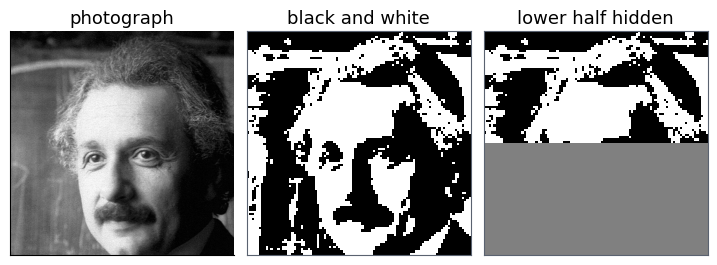

In [5]:
def hide_lower_half(s):
    cue = s.copy()                            # copy, so that the stored portrait stays intact
    cue[N_portrait // 2:] = 0.0               # rows 49 to 96 become undecided
    return cue

plot_portrait_preparation(xi_portraits[0], hide_lower_half(xi_portraits[0]), portrait_shape)

All six portraits go through the same treatment. The row below is the complete information the network receives in the test of Section 6.

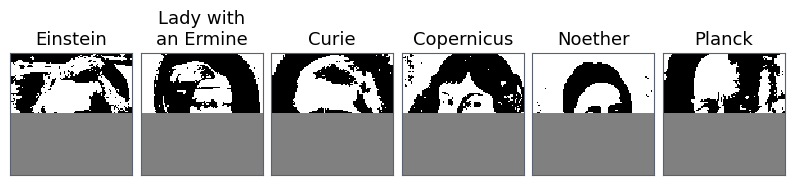

In [6]:
titles = [portrait_names[key] for key in portrait_keys]
plot_image_row([hide_lower_half(x) for x in xi_portraits], titles, portrait_shape, "portraits_hidden", (10, 2.3))

## 2. Images as patterns of spins

To store an image in a physical system we write it as a list of numbers $\pm1$. We use smaller images while we build the method, namely handwritten digits of $28\times28$ pixels derived from the MNIST training set [2]. A pixel of a training image counts as ink when its grey value exceeds half of the maximum. For each digit from 0 to 9, a pixel of the stored image is ink when it is ink in more than half of the training images of that digit, so one typical image represents each digit. The file stores bits $b_i$, with $b_i=1$ for ink and $b_i=0$ for background. We turn each bit into a spin,

$$s_i = 1-2b_i, \tag{1}$$

so a white background pixel has $s_i=+1$ and a black ink pixel has $s_i=-1$. Reading the image row after row gives one long vector with $N=28\times28=784$ entries. A stored vector is called a pattern and is written $\boldsymbol\xi^\mu$, where $\mu$ numbers the patterns and $\xi_i^\mu$ is its value at pixel $i$. When a pattern is a digit we write the digit in brackets, so $\boldsymbol\xi^{(3)}$ is the digit 3.

The next cell applies equation (1). Its input is the bit array of shape `(10, 28, 28)`, and its output is `xi_digits` of shape `(10, 784)`, with one digit per row. The vectors `three`, `eight` and `zero` have shape `(784,)`.

In [7]:
digits = np.load(DATA / "lab078_mnist_class_means.npz")
digit_shape = digits["bits"].shape[1:]                 # (28, 28)

# reshape(10, -1) keeps 10 rows and lets NumPy compute the row length, 28 * 28 = 784
bits = digits["bits"].reshape(10, -1)
xi_digits = 1.0 - 2.0 * bits                           # equation (1), applied to every entry
N_digit = xi_digits.shape[1]

three, eight, zero = xi_digits[3], xi_digits[8], xi_digits[0]

print("patterns", xi_digits.shape[0], "  spins per pattern", N_digit)
print("values present", np.unique(xi_digits))
print("ten entries from row 15 of the digit 3  ", three.reshape(digit_shape)[14, 9:19].astype(int))

patterns 10   spins per pattern 784
values present [-1.  1.]
ten entries from row 15 of the digit 3   [ 1  1 -1 -1 -1 -1 -1 -1 -1 -1]


The upper left panel shows the digit 3 and the upper right panel enlarges the small square marked in orange, with the value of each pixel written on it. The strip at the bottom is the same image after the rows have been placed one after another. It looks unlike a digit, yet it contains the same 784 numbers.

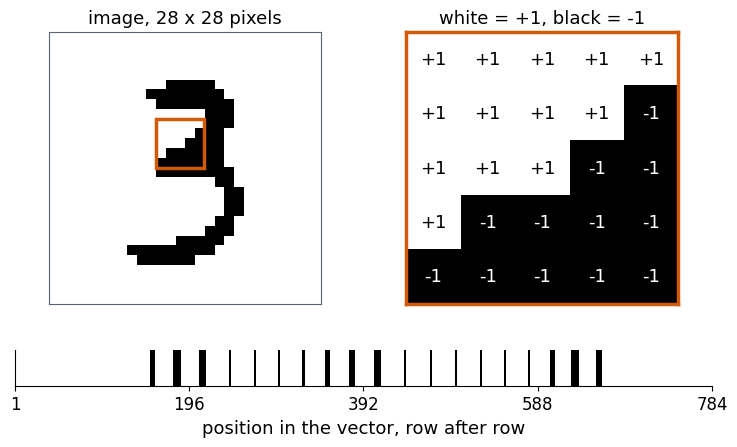

In [8]:
plot_digit_as_vector(three, digit_shape)

## 3. A network with one spin per pixel

The network has one spin $s_i=\pm1$ for every pixel, with $i=1,\dots,N$, so a configuration of the network is itself a black-and-white image. A spin plays the role of a neuron that can be in one of two states. Every pair of spins $i,j$ is connected by a number $J_{ij}$ called a coupling. The couplings are symmetric, $J_{ij}=J_{ji}$, and a spin has no coupling to itself, $J_{ii}=0$. There are no layers and no separate input and output units. The same spins receive the damaged image at the start and show the answer at the end.

The sketch draws a network of nine spins arranged as a small image, with a line for each coupling. White circles are spins $+1$ and black circles are spins $-1$. A network of $N$ spins has $N(N-1)/2$ couplings, which the cell below evaluates for the sketch and for one digit image.

couplings in the sketch 36
couplings for one digit image 306936


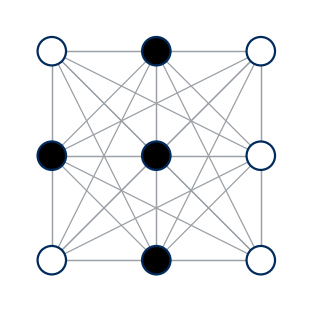

In [9]:
plot_network_sketch([1, -1, 1, -1, -1, 1, 1, -1, 1])

pairs_digit = N_digit * (N_digit - 1) // 2              # // is division without remainder
print("couplings in the sketch", 9 * 8 // 2)
print("couplings for one digit image", pairs_digit)

## 4. Hebbian couplings

The memory of the network sits entirely in its couplings, so storing a pattern means choosing the $J_{ij}$. Hebb proposed that the connection between two neurons becomes stronger when they are active together [3], and Hopfield used this idea for spins [1]. In the spin version the relevant question is whether two pixels agree. If they have the same value in a pattern, both $+1$ or both $-1$, their coupling receives a positive contribution, and if they have opposite values it receives a negative one. Adding the contributions of all $p$ patterns and dividing by $N$ gives the Hebbian rule,

$$J_{ij}=\frac1N\sum_{\mu=1}^{p}\xi_i^\mu\,\xi_j^\mu\quad (i\neq j),\qquad J_{ii}=0. \tag{2}$$

For one pattern the table of all products $\xi_i^\mu\xi_j^\mu$ is the outer product $\boldsymbol\xi^\mu(\boldsymbol\xi^\mu)^{\mathsf T}$, a matrix with $N$ rows and $N$ columns. Storing several patterns then means adding their outer products. Section 5 shows why each pattern survives this addition. We store the digits 3 and 8.

The function `hebb` implements equation (2). Its input is an array `patterns` of shape `(p, N)` with one pattern per row, and its output is the coupling matrix `J` of shape `(N, N)`.

In [10]:
def hebb(patterns):
    N = patterns.shape[1]

    # patterns.T has shape (N, p), so patterns.T @ patterns has shape (N, N).
    # Its entry (i, j) is sum_mu xi_i^mu xi_j^mu, the sum of the outer products in equation (2).
    J = patterns.T @ patterns / N

    # J_ii = 0, no spin is coupled to itself
    np.fill_diagonal(J, 0.0)
    return J

J_two = hebb(np.array([three, eight]))                  # the input array has shape (2, 784)

assert np.array_equal(J_two, J_two.T)                   # symmetric, J_ij = J_ji
assert np.all(np.diag(J_two) == 0)                      # zero diagonal
print("shape of J", J_two.shape)

shape of J (784, 784)


The three panels show the outer product of the digit 3, the outer product of the digit 8 and their sum. The sum equals $N J_{ij}$ away from the diagonal, and the diagonal is removed afterwards by the rule $J_{ii}=0$. Blue entries are positive, orange entries are negative and white entries vanish, as the colour bar shows. The first two panels contain only the values $\pm1$, so they look paler than the third, whose entries reach $\pm2$. Most entries are blue, because most pixels are background and two background pixels agree. Each ink pixel disagrees with the background, so it produces one orange row and one orange column, and these lines form the stripes.

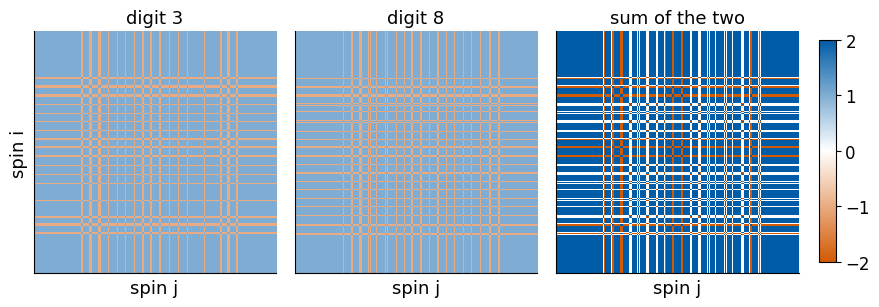

In [11]:
outer3 = np.outer(three, three)                        # shape (784, 784), entries xi_i xi_j
outer8 = np.outer(eight, eight)
plot_outer_products(outer3, outer8)

One row of this matrix can be drawn as an image again. We choose a pixel near the centre that is ink in both digits, marked by the red square, and draw its couplings to all other pixels. A blue pixel in the right panel tends to take the same value as the marked pixel and an orange pixel, such as the background of both digits, tends to take the opposite value. White pixels are those on which the two digits pull in opposite directions, so their contributions cancel. The marked pixel itself is white as well, because $J_{ii}=0$.

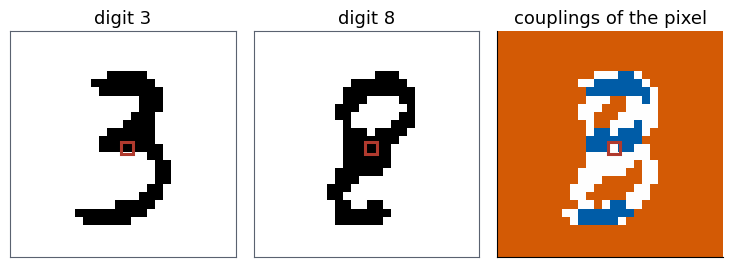

In [12]:
plot_pixel_couplings(three, eight, J_two, digit_shape)

## 5. Energy, local field and recall of a damaged digit

### Energy of a configuration

The couplings define a score for every possible image, and this score is the energy

$$E(\mathbf s)=-\frac12\sum_{i,j=1}^{N}J_{ij}\,s_i\,s_j. \tag{3}$$

The double sum counts every pair twice, once as $(i,j)$ and once as $(j,i)$, and the factor $\frac12$ compensates for this. A positive coupling lowers the energy when the two spins agree, and a negative coupling lowers it when they disagree. Low energy therefore means that the image respects many of the relations stored in the couplings.

Four spins are enough to see all of this, because they have only $2^4=16$ configurations. We store the single pattern $\boldsymbol\xi=(+1,-1,+1,+1)$ and leave out the factor $1/N$, so that the couplings $J_{ij}=\xi_i\xi_j$ are integers. The double sum over all $i,j$ of $\xi_i\xi_js_is_j$ factorises into $(\sum_i\xi_is_i)^2$. This sum also contains the four diagonal terms $i=j$, each equal to one, which equation (2) excludes and which we therefore subtract,

$$E(\mathbf s)=-\frac12\Big[\underbrace{\Big(\sum_i\xi_is_i\Big)^2}_{\text{all pairs } i,j}-\underbrace{4}_{\text{diagonal terms } i=j}\Big]=2-\frac12(\boldsymbol\xi\cdot\mathbf s)^2 .$$

The product $\boldsymbol\xi\cdot\mathbf s$ can take the values $\pm4$, $\pm2$ and $0$, so only three energies can occur.

The next cell defines the energy (3) and goes through all 16 configurations. The function `energy` takes `J` of shape `(N, N)` and `s` of shape `(N,)` and returns one number. The function `itertools.product([1, -1], repeat=4)` produces every list of four values $\pm1$. The output groups the configurations by energy.

In [13]:
def energy(J, s):
    # J @ s has entries sum_j J_ij s_j, and s @ (J @ s) sums s_i times them, equation (3)
    return -0.5 * s @ (J @ s)

def as_text(s):
    return "".join("+" if value > 0 else "-" for value in s)   # for example +-++

xi_four = np.array([1, -1, 1, 1])
J_four = np.outer(xi_four, xi_four) - np.eye(4, dtype=int)     # subtracting the identity sets J_ii = 0

levels = {}                                                    # energy -> list of configurations
for configuration in itertools.product([1, -1], repeat=4):
    s = np.array(configuration)
    E = float(energy(J_four, s))
    assert E == 2 - 0.5 * (xi_four @ s) ** 2                   # the formula derived above
    if E not in levels:
        levels[E] = []
    levels[E].append(as_text(s))

for E in sorted(levels):
    print(f"E = {E:+.0f}   {len(levels[E])} configurations   ", " ".join(levels[E]))
assert {E: len(group) for E, group in levels.items()} == {-6.0: 2, 0.0: 8, 2.0: 6}

E = -6   2 configurations    +-++ -+--
E = +0   8 configurations    ++++ ++-- +-+- +--+ -++- -+-+ --++ ----
E = +2   6 configurations    +++- ++-+ +--- -+++ --+- ---+


The lowest energy $-6$ belongs to two configurations, the stored pattern `+-++` and its black-and-white inverse `-+--`. The inverse always appears, because equation (3) does not change when every spin changes sign. The stored pattern has become the bottom of an energy valley, and this is what we mean by a memory in this network.

### Local field and the update of one spin

Spin $i$ feels the other spins through its local field

$$\phi_i=\sum_{j=1}^{N}J_{ij}\,s_j. \tag{4}$$

The field is the sum of the votes of all other spins. Recall consists of visiting the spins one at a time and aligning the visited spin with its field,

$$s_i\leftarrow\operatorname{sign}(\phi_i), \tag{5}$$

while a spin with $\phi_i=0$ keeps its value. The visits happen one at a time because each flip changes the fields of all other spins, and the next visited spin must see the updated image. The argument below relies on this. To see what rule (5) does to the energy, we flip one spin $k$ and collect the part of equation (3) that contains $s_k$. Because $J_{kj}=J_{jk}$ and $J_{kk}=0$, this part is

$$-\frac12\underbrace{\sum_{j}J_{kj}s_ks_j}_{i=k}-\frac12\underbrace{\sum_{i}J_{ik}s_is_k}_{j=k}=-s_k\,\phi_k .$$

The flip changes the sign of this contribution and leaves the rest of the energy unchanged, so with $s_k$ and $\phi_k$ taken before the flip,

$$\Delta E=2\,s_k\,\phi_k. \tag{6}$$

A spin is flipped by rule (5) only when it points against its field, which means $s_k\phi_k<0$ and therefore $\Delta E<0$. Every flip lowers the energy, and since the number of configurations is finite the process has to stop. It stops in a configuration where no single flip can lower the energy, a local minimum.

The function `relax` implements rule (5). Its inputs are the couplings `J` of shape `(N, N)`, a starting image `s` of shape `(N,)` and a random generator `rng`, which chooses the order of the visits. It returns a pair, the final image of shape `(N,)` and the list `path` of all images visited, so a call is written `final, path = relax(J, s, rng)`. The list has one entry more than there are flips. The function `damage` flips a chosen fraction of the pixels of a pattern and returns the damaged image with the positions of the flipped pixels.

In [14]:
TOL = 1e-9     # computed fields carry rounding errors of about 1e-15, so a field below TOL counts as zero

def relax(J, s, rng):
    s = s.copy()                                 # the array passed in stays unchanged
    path = [s.copy()]                            # the images visited, starting with the cue
    while True:
        changed = False
        # one sweep visits every spin once, in a random order
        for i in rng.permutation(len(s)):
            # J[i] is row i of J, so J[i] @ s = sum_j J_ij s_j, equation (4)
            phi_i = J[i] @ s
            # s_i phi_i < 0 means that the spin points against its field, so rule (5) flips it
            if abs(phi_i) > TOL and s[i] * phi_i < 0:
                s[i] = -s[i]
                changed = True
                path.append(s.copy())
        # a sweep without any flip means that every spin agrees with its field
        if not changed:
            return s, path

def damage(pattern, fraction, rng):
    cue = pattern.copy()
    number_of_flips = int(round(fraction * len(cue)))
    # choose that many different positions, replace=False forbids repeating a position
    chosen = rng.choice(len(cue), size=number_of_flips, replace=False)
    cue[chosen] *= -1                            # flip the spins at the chosen positions
    return cue, chosen

### Recall of a damaged digit

The network stores the digits 3 and 8. We take the digit 3 and flip 20 per cent of its pixels at random, which gives 157 wrong pixels out of 784. This damaged image is the cue, the starting configuration of the spins. The network then runs rule (5).

The next cell produces the cue `cue` of shape `(784,)`, the final image `final_two` of the same shape and the list `path_two`. From the list it computes `E_two`, the energy (3) per spin after each flip, with one entry per image of the path. It also records which pixel each flip changed. Comparing two consecutive images with `!=` gives a boolean mask, and `np.flatnonzero` returns the positions where the mask is `True`.

In [15]:
rng_digit = np.random.default_rng(1401)
cue, damaged = damage(three, 0.20, rng_digit)
final_two, path_two = relax(J_two, cue, rng_digit)

# energy per spin of every image along the path, one entry per image
E_two = np.array([energy(J_two, s) / N_digit for s in path_two])

# for each pair of consecutive images, find the one pixel that differs
flipped = []
for before, after_flip in zip(path_two[:-1], path_two[1:]):
    changed_pixels = np.flatnonzero(before != after_flip)
    flipped.append(int(changed_pixels[0]))

print("damaged pixels", len(damaged), "  flips", len(flipped), "  wrong pixels after recall", int(np.sum(final_two != three)))
print("energy per spin at the start and at the end", round(E_two[0], 3), round(E_two[-1], 3))

assert np.array_equal(final_two, three)
assert np.all(np.diff(E_two) < 0)                       # the energy fell at every flip
assert set(flipped) == set(damaged.tolist())            # each flip repaired one damaged pixel

damaged pixels 157   flips 157   wrong pixels after recall 0
energy per spin at the start and at the end -0.296 -0.801


The upper row shows five moments of the recall and the lower panel shows the energy per spin after each flip, with orange dots at the moments shown above. The energy falls at every flip. The run needs 157 flips for 157 damaged pixels, because in this run every flip repaired one damaged pixel and no correct pixel was touched.

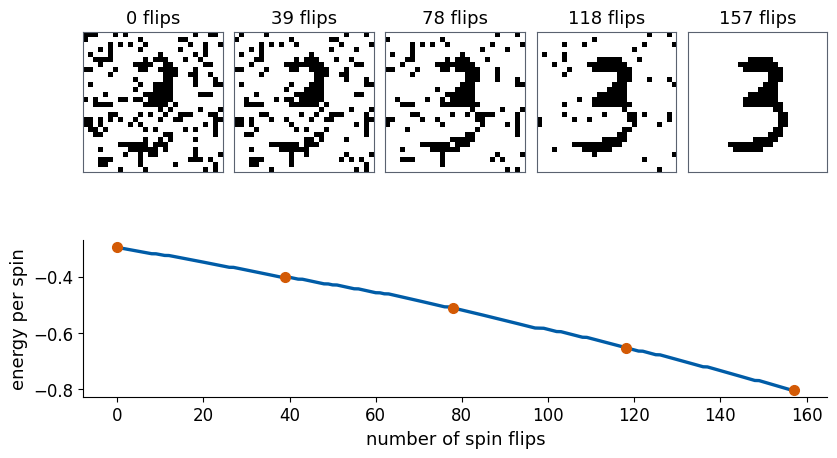

In [16]:
plot_recall(path_two, E_two, digit_shape)

Equation (6) can be tested directly on the damaged digit. We pick the first spin that points against its field, compute the predicted change of energy from its field, and compare it with the change obtained from equation (3) before and after the flip. The array `phi` has shape `(784,)`, and the mask `cue * phi < 0` is `True` at the spins that point against their field. The numbers printed are changes of the total energy, whereas the figure above shows the energy per spin. Index 0 in the code is the spin $i=1$, the upper left corner of the image.

In [17]:
phi = J_two @ cue                                   # all local fields, equation (4), shape (784,)
against_field = cue * phi < 0                       # boolean mask, True where s_i phi_i < 0
k = int(np.flatnonzero(against_field)[0])           # position of the first such spin

after = cue.copy()
after[k] *= -1                                      # the image after flipping spin k

predicted = 2 * cue[k] * phi[k]                     # equation (6)
measured = energy(J_two, after) - energy(J_two, cue)
print("spin index in the code", k, "  predicted change", round(predicted, 6), "  change from the energy", round(measured, 6))
assert abs(predicted - measured) < 1e-9

spin index in the code 0   predicted change -2.173469   change from the energy -2.173469


### Overlaps and the vote of the stored patterns

The energy argument guarantees that the recall ends in a local minimum. Which minimum it reaches depends on how similar the current image is to each stored pattern, and we measure this similarity with the overlap

$$m_\mu=\frac1N\sum_{j=1}^{N}\xi_j^\mu\,s_j. \tag{7}$$

The overlap equals $1$ when the image coincides with the pattern, $-1$ for the inverted pattern, and it is close to $0$ for an unrelated image. Inserting the Hebbian rule (2) into the field (4) and removing the term $j=i$ gives

$$\phi_i=\sum_{\mu=1}^{p}\xi_i^\mu\underbrace{\frac1N\sum_{j}\xi_j^\mu s_j}_{m_\mu}-\frac1N\sum_{\mu=1}^{p}\underbrace{(\xi_i^\mu)^2}_{1}\,s_i=\sum_{\mu=1}^{p}\xi_i^\mu\,m_\mu-\frac pN\,s_i. \tag{8}$$

According to equation (8), each stored pattern votes for its own value at pixel $i$, and the weight of its vote is its overlap with the current image.

The function `field_from_overlaps` implements equations (7) and (8). Its inputs are `patterns` of shape `(p, N)` and an image `s` of shape `(N,)`. The vector `m` has shape `(p,)`, and the output, all $N$ fields, has shape `(N,)`. The cell compares the result with `J_two @ cue`. The printed difference is rounding error of the computer, of order $10^{-16}$.

In [18]:
def field_from_overlaps(patterns, s):
    N = patterns.shape[1]
    p = len(patterns)
    m = patterns @ s / N                    # equation (7), shape (p,)
    # patterns.T @ m has entries sum_mu xi_i^mu m_mu, shape (N,), the vote in equation (8)
    return patterns.T @ m - p / N * s

two_digits = np.array([three, eight])       # shape (2, 784)
difference = field_from_overlaps(two_digits, cue) - J_two @ cue
assert np.allclose(field_from_overlaps(two_digits, cue), J_two @ cue)
print("largest difference between the two ways of computing the field", float(np.abs(difference).max()))

largest difference between the two ways of computing the field 2.220446049250313e-16


### Stability of a stored pattern

A stored pattern is stable when the network, placed on it, changes nothing. We set $\mathbf s=\boldsymbol\xi^\nu$ in equation (8). The overlap with pattern $\nu$ is then $1$, and the overlap with another pattern $\mu$ is the overlap between the two patterns, $q_{\mu\nu}=\frac1N\boldsymbol\xi^\mu\cdot\boldsymbol\xi^\nu$. Multiplying the field by $\xi_i^\nu$ gives

$$\xi_i^\nu\,\phi_i=\underbrace{1}_{\text{own vote}}+\underbrace{\sum_{\mu\neq\nu}\xi_i^\nu\,\xi_i^\mu\,q_{\mu\nu}}_{\text{votes of the other patterns}}-\frac pN. \tag{9}$$

Pattern $\nu$ is stable when this quantity is positive at every pixel, since every spin then agrees with its field. This is why several patterns can live in the same couplings. Each pattern has a vote of weight one for itself, and the others can only disturb it through their overlaps with it. For the digits 3 and 8 the worst pixels are those where the digits differ, with $\xi_i^{(3)}\xi_i^{(8)}=-1$, and there equation (9) gives $1-q_{3,8}-2/N$.

The overlaps also give the energy at the end of the recall of Section 5. We insert the Hebbian rule (2) into equation (3). As for the four spins of Section 5, the double sum over $i\neq j$ of $\xi_i^\mu s_i\,\xi_j^\mu s_j$ is the square of the full sum minus its $N$ diagonal terms,

$$\sum_{i\neq j}\xi_i^\mu s_i\,\xi_j^\mu s_j=\Big(\sum_i\xi_i^\mu s_i\Big)^2-N=N^2m_\mu^2-N ,$$

and with the prefactor $-\frac1{2N}$ and the division by $N$ this gives $E/N=-\frac12\sum_\mu m_\mu^2+p/(2N)$. On the digit 3 the two overlaps are $1$ and $q_{3,8}$.

The function `stability_margin` returns the left side of equation (9) for all pixels, as an array of shape `(N,)`. Its inputs are `patterns` of shape `(p, N)` and the row number `nu` of the pattern under test. The cell also compares the predicted final energy per spin with the last entry of `E_two`.

In [19]:
def stability_margin(patterns, nu):
    xi_nu = patterns[nu]                                # the pattern under test, shape (N,)
    phi = field_from_overlaps(patterns, xi_nu)          # the fields when s = xi^nu
    return xi_nu * phi                                  # entry by entry, xi_i^nu phi_i, equation (9)

q_38 = three @ eight / N_digit                          # overlap between the two digits

for nu, name in enumerate(("3", "8")):
    margin = stability_margin(two_digits, nu)
    print(f"digit {name}   smallest margin {margin.min():.3f}   pixels against their field {int(np.sum(margin < -TOL))}")
print("1 - q_38 - 2/N =", round(1 - q_38 - 2 / N_digit, 3))

predicted_energy = -(1 + q_38 ** 2) / 2 + 2 / (2 * N_digit)
print("final energy per spin, predicted", round(predicted_energy, 3), "  from the recall", round(E_two[-1], 3))

digit 3   smallest margin 0.219   pixels against their field 0
digit 8   smallest margin 0.219   pixels against their field 0
1 - q_38 - 2/N = 0.219
final energy per spin, predicted -0.801   from the recall -0.801


Both digits are stable at the same time, each with the smallest margin $1-q_{3,8}-2/N$. The network therefore has two valleys, and stability alone cannot say which one a cue will reach.

### The pattern reached from a cue

Which of the two valleys the recall reaches is decided by the cue. At a pixel where the digits 3 and 8 agree, both patterns vote for the same value, and a damaged pixel of this kind is repaired whichever pattern is ahead. At a pixel where they differ, $\xi_i^{(8)}=-\xi_i^{(3)}$, and equation (8) becomes

$$\phi_i=\xi_i^{(3)}\big(m_{(3)}-m_{(8)}\big)-\frac2N\,s_i ,$$

so the field follows the digit with the larger overlap. The next cell computes the two overlaps of the cue and checks at how many of the disputed pixels the field already points to the digit 3. The array `m_path_two` contains the overlaps along the whole recall. It is obtained from the list of images, turned into an array of shape `(158, 784)` with one image per row. Its transpose has shape `(784, 158)`, so `two_digits @ path_array.T` has shape `(2, 158)`, one row per stored digit and one column per image.

overlaps of the cue with the digits 3 and 8 [0.6, 0.48]
disputed pixels 87   of which the field points to the digit 3 at 87


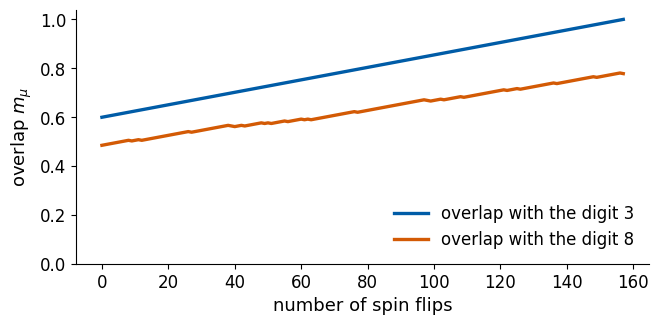

In [20]:
m_cue = two_digits @ cue / N_digit                    # equation (7), shape (2,)
print("overlaps of the cue with the digits 3 and 8", m_cue.round(2).tolist())

disputed = three != eight                             # mask of the pixels where the digits differ
phi_cue = J_two @ cue
follows_three = np.sign(phi_cue[disputed]) == three[disputed]
print("disputed pixels", int(disputed.sum()), "  of which the field points to the digit 3 at", int(follows_three.sum()))

path_array = np.array(path_two)                       # shape (158, 784)
m_path_two = two_digits @ path_array.T / N_digit      # shape (2, 158)
plot_overlap_curves(m_path_two, ["overlap with the digit 3", "overlap with the digit 8"], "recall_overlaps")

The cue has the larger overlap with the digit 3, so all disputed pixels already vote for the 3 at the start, and the overlap with the 3 rises to one. The overlap with the 8 rises as well, to $q_{3,8}$, because the two digits share most of their pixels. A cue damaged so strongly that its overlap with the 8 is larger would end at the 8, even though the 3 is stable, and Exercise 1 tests this.

## 6. Recall of half portraits

We now return to the portraits. One portrait has $N=96\times96=9216$ pixels, so the matrix $J_{ij}$ would have about 85 million entries, which take about 680 megabytes at 8 bytes per number. Equation (8) avoids this matrix, because the field needs only the $p$ overlaps and the patterns themselves.

Hidden pixels start with the value $s_i=0$, which we call undecided. They contribute nothing to the overlaps, so at the start the overlaps are determined by the visible upper half alone. An undecided spin takes the sign of its field as soon as it is visited. The energy argument of Section 5 still applies, because the part of the energy containing $s_k$ is $-s_k\phi_k$, and a change from $s_k=0$ to $\operatorname{sign}(\phi_k)$ changes the energy by $-|\phi_k|$, which is negative.

When spin $i$ changes from $s_i$ to a new value, only the term $j=i$ of the sum (7) changes, so every overlap changes by

$$\Delta m_\mu=\frac1N\,\xi_i^\mu\,\big(s_i^{\text{new}}-s_i\big).$$

The function `relax_portrait` applies rule (5) with the field (8) and this update of the overlaps. Its inputs are the starting image `s` of shape `(N,)`, `patterns` of shape `(p, N)` and the random generator that sets the order of the visits. The vector `m` has shape `(p,)`, and `patterns[:, i]` is column $i$, the $p$ values $\xi_i^\mu$ of one pixel, of shape `(p,)`. The function returns the final image of shape `(N,)`.

In [21]:
def relax_portrait(s, patterns, rng):
    N = patterns.shape[1]
    p = len(patterns)
    s = s.copy()
    m = patterns @ s / N                                    # equation (7), shape (p,)

    for sweep in range(300):                                # safety limit, recall needs only a few sweeps
        changed = False
        for i in rng.permutation(N):
            xi_at_i = patterns[:, i]                        # the values xi_i^mu of pixel i, shape (p,)
            phi_i = xi_at_i @ m - p / N * s[i]              # equation (8)

            # rule (5), a field smaller than TOL leaves the spin as it is
            new = 1.0 if phi_i > TOL else (-1.0 if phi_i < -TOL else s[i])

            if new != s[i]:
                m += (new - s[i]) * xi_at_i / N             # the update of the overlaps given above
                s[i] = new
                changed = True
        if not changed:
            return s
    raise RuntimeError("no fixed point reached")

The six portraits are much less alike than the digits. The next cell computes all their mutual overlaps $q_{\mu\nu}$ as the matrix `Q_portraits` of shape `(6, 6)`. Its diagonal contains the overlap of each portrait with itself, equal to one, so we subtract the identity matrix before searching for the largest entry between two different portraits. The cell also evaluates the stability margin (9) of every portrait.

In [22]:
Q_portraits = xi_portraits @ xi_portraits.T / N_portrait        # q_mu_nu, shape (6, 6)
off_diagonal = Q_portraits - np.eye(6)                          # the diagonal entries become 0
print("largest overlap between two portraits", round(float(np.abs(off_diagonal).max()), 2))

margins = [stability_margin(xi_portraits, nu).min() for nu in range(6)]
print("smallest stability margin of each portrait", np.round(margins, 2).tolist())
assert min(margins) > 0                                         # all six are stable

largest overlap between two portraits 0.3
smallest stability margin of each portrait [0.13, 0.47, 0.23, 0.59, 0.6, 0.38]


All six margins are positive, so all six portraits are stable. The next cell tests whether they are also reached from their upper halves. Its input is one cue per portrait, and its output is `restored` of shape `(6, 9216)`. One random generator supplies the visiting orders of all six recalls. The array `wrong` of shape `(6,)` counts the wrong pixels of each portrait.

In [23]:
rng_portrait = np.random.default_rng(1403)

restored = []
for x in xi_portraits:
    restored.append(relax_portrait(hide_lower_half(x), xi_portraits, rng_portrait))
restored = np.array(restored)                                   # shape (6, 9216)

state_after_six = rng_portrait.bit_generator.state              # the position in the random sequence, see Section 8

wrong = np.sum(restored != xi_portraits, axis=1)                # axis=1 counts along each row
print("wrong pixels per portrait", wrong.tolist(), " out of", N_portrait)
assert np.all(wrong == 0)
assert np.array_equal(restored.reshape(6, n_side, n_side), stored_file["restored"])

wrong pixels per portrait [0, 0, 0, 0, 0, 0]  out of 9216


All six portraits come back with no wrong pixel among the 9216, and the assertion in the cell stops the notebook if this ever fails. The upper row is the input and the lower row is the output of the network.

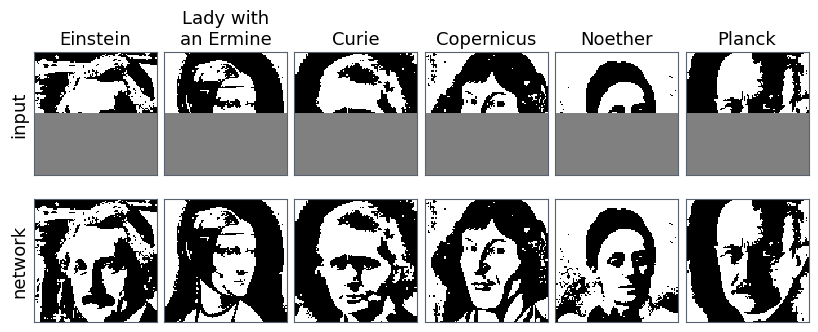

In [24]:
cues = [hide_lower_half(x) for x in xi_portraits]
plot_input_output(cues, restored, titles, portrait_shape)

For the half portrait of Einstein the overlap with the correct pattern starts at $0.5$, because half of the pixels agree and the other half are undecided. In equation (8) the correct portrait wins the vote at every pixel from the start when its overlap exceeds the sum of the magnitudes of all other overlaps plus $p/N$. The next cell draws the overlaps of Einstein, with `start_overlap` and `end_overlap` of shape `(6,)`, and evaluates this start margin for each of the six portraits.

Einstein, start [0.5, 0.06, 0.15, 0.02, -0.04, 0.09]
Einstein, end   [1.0, 0.2, 0.3, 0.1, -0.09, 0.17]
margin at the start = own overlap - sum of |other overlaps| - p/N
  Einstein            +0.133
  Lady with an Ermine +0.215
  Curie               +0.036
  Copernicus          +0.181
  Noether             +0.107
  Planck              +0.023


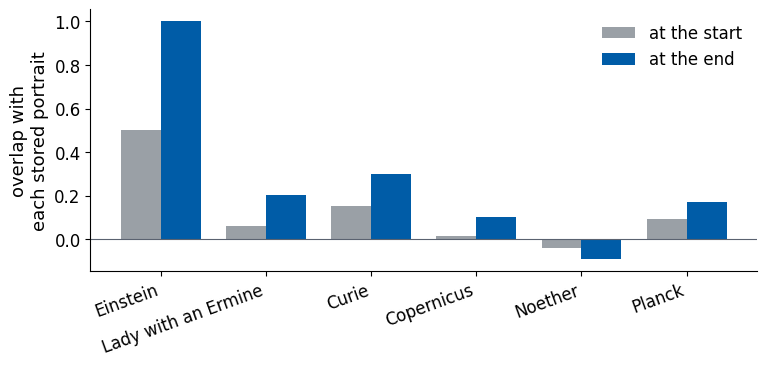

In [25]:
start_overlap = xi_portraits @ hide_lower_half(xi_portraits[0]) / N_portrait     # equation (7)
end_overlap = xi_portraits @ restored[0] / N_portrait
labels = [portrait_names[k].replace("\n", " ") for k in portrait_keys]
plot_start_end_overlaps(start_overlap, end_overlap, labels)
print("Einstein, start", start_overlap.round(2).tolist())
print("Einstein, end  ", end_overlap.round(2).tolist())

print("margin at the start = own overlap - sum of |other overlaps| - p/N")
for nu, name in enumerate(labels):
    m_start = xi_portraits @ hide_lower_half(xi_portraits[nu]) / N_portrait
    others = np.abs(m_start).sum() - abs(m_start[nu])        # sum of |m_mu| over the five portraits mu != nu
    start_margin = m_start[nu] - others - 6 / N_portrait
    print(f"  {name:20s}{start_margin:+.3f}")
    assert start_margin > 0

The margin is positive for all six portraits, so each portrait is ahead at every pixel from the first visit. It is smallest for Planck and Curie. Exercise 3 stores one more image and shows that the portraits lost in that case need not be those with the smallest margin here. At the end of the recall the overlap with the correct portrait equals one, and the others have become the overlaps between the stored portraits themselves.

## 7. Overload with a third digit

We now add the digit 0 to the stored digits 3 and 8 and start from the same damaged digit 3 as in Section 5. The next cell builds the couplings of the three digits from `triple` of shape `(3, 784)`, runs `relax` from the same cue, and compares the final image `final_three` with each digit. It also forms the pixel-wise majority of the three digits. In `triple.sum(axis=0)` each entry is the sum of three values $\pm1$, which is odd and therefore never zero, and its sign is the value held by at least two of the digits.

In [26]:
triple = np.array([three, eight, zero])
J_three = hebb(triple)
rng_three = np.random.default_rng(1402)
final_three, path_three = relax(J_three, cue, rng_three)

wrong_three = [int(np.sum(final_three != x)) for x in triple]
print("flips", len(path_three) - 1)
print("wrong pixels against the digits 3, 8, 0  ", wrong_three)

majority = np.sign(triple.sum(axis=0))                  # shape (784,)
print("wrong pixels against the majority image ", int(np.sum(final_three != majority)))
assert min(wrong_three) > 0 and np.array_equal(final_three, majority)

flips 184
wrong pixels against the digits 3, 8, 0   [39, 48, 91]
wrong pixels against the majority image  0


The network settles after 184 flips in an image that differs from the digit 3 in 39 pixels and from the other two digits in even more. At every pixel the final image takes the value held by the majority of the three stored digits. An image built in this way from stored patterns is called a mixture state. It is a false memory, a valley of the energy that nobody stored.

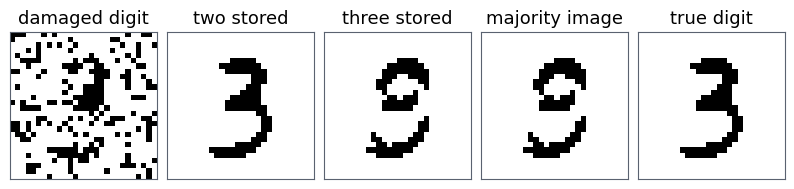

In [27]:
panels = (cue, final_two, final_three, majority, three)
panel_titles = ("damaged digit", "two stored", "three stored", "majority image", "true digit")
plot_image_row(panels, panel_titles, digit_shape, "overload", (10, 2.6))

### Loss of stability of the digits

Most pixels of every digit are white background, so the overlaps $q_{\mu\nu}$ between different digits are large, as the next cell prints. Suppose the network sits on the digit 3, and consider a pixel at which the digits 8 and 0 both disagree with the digit 3. Equation (9) with $p=3$ gives

$$\xi_i^{(3)}\,\phi_i=1-q_{3,8}-q_{3,0}-\frac{3}{N}.$$

The two overlaps add up to more than one, so this quantity is negative and the pixel flips. At a pixel where only one of the other digits disagrees, the two votes have opposite signs and equation (9) gives $1+q-q'-3/N$, with $q$ the overlap of the agreeing digit and $q'$ that of the disagreeing one. This is positive, because $q'-q$ is well below one, and at a pixel where both others agree all votes are positive. The stored digit 3 is therefore unstable only at the outvoted pixels, even with no damage at all, and the same argument holds for the digits 8 and 0.

The next cell tests this for each digit. The mask `unstable` marks the pixels with a negative margin (9), and the mask `outvoted` marks the pixels at which both other digits differ from the digit under test, with `&` meaning "and" between two masks. The argument above requires the two masks to coincide.

In [28]:
Q = triple @ triple.T / N_digit                          # overlaps q_mu_nu, shape (3, 3)
print("overlaps between the digits 3, 8, 0")
print(Q.round(2))
print("fraction of ink pixels in the digits 3, 8, 0  ", (triple < 0).mean(axis=1).round(2))

names = ["3", "8", "0"]
for a in range(3):
    b, c = [index for index in range(3) if index != a]   # the two other digits

    unstable = stability_margin(triple, a) < -TOL        # pixels against their field
    outvoted = (triple[b] != triple[a]) & (triple[c] != triple[a])
    assert np.array_equal(unstable, outvoted)

    print(f"digit {names[a]}   1 - q - q' - 3/N = {1 - Q[a, b] - Q[a, c] - 3 / N_digit:+.3f}   pixels against their field {int(unstable.sum())}")

overlaps between the digits 3, 8, 0
[[1.   0.78 0.67]
 [0.78 1.   0.65]
 [0.67 0.65 1.  ]]
fraction of ink pixels in the digits 3, 8, 0   [0.11 0.13 0.17]
digit 3   1 - q - q' - 3/N = -0.450   pixels against their field 39
digit 8   1 - q - q' - 3/N = -0.427   pixels against their field 48
digit 0   1 - q - q' - 3/N = -0.318   pixels against their field 91


The failing pixels of the digit 3 are the 39 at which it is outvoted by the two other digits, which is also the number of wrong pixels found above. In Section 5 the digit 3 was stable, because with two stored digits the corresponding quantity $1-q_{3,8}-2/N$ is positive, and it was reached because the cue had the larger overlap with it. With three stored digits neither statement helps, since none of the three digits is stable any more.

### Arrival at the majority image

Equation (8) also explains why the network stops at the majority image. Let the three overlaps be $m_{(3)}$, $m_{(8)}$ and $m_{(0)}$. If all three are positive and any two of them together exceed the third, then at every pixel the two digits that agree outvote the one that disagrees, so the sign of the field is the majority value. The next cell evaluates the overlaps of the cue and of the final image, `m_start_three` and `m_end_three`, both of shape `(3,)`, tests this condition, and compares the sign of the field of the cue with the majority image. It then repeats both tests for each of the 185 images along the recall, using the overlaps in an array of shape `(3, 185)` and the fields of the images in an array of shape `(185, 784)`, and plots the overlaps.

overlaps with the digits 3, 8, 0 at the start [0.6, 0.48, 0.35]  any two outweigh the third: True
overlaps with the digits 3, 8, 0 at the end   [0.9, 0.88, 0.77]  any two outweigh the third: True
pixels whose field at the start has the majority sign 784 of 784
pixels of the cue that differ from the majority image 184
smallest value of s_i phi_i in the final image 0.741
three-digit overlaps of the final image [0.901, 0.878, 0.768]   3/N = 0.0038
images along the recall that satisfy the condition 185 of 185
images along the recall whose field has the majority sign at every pixel 185 of 185


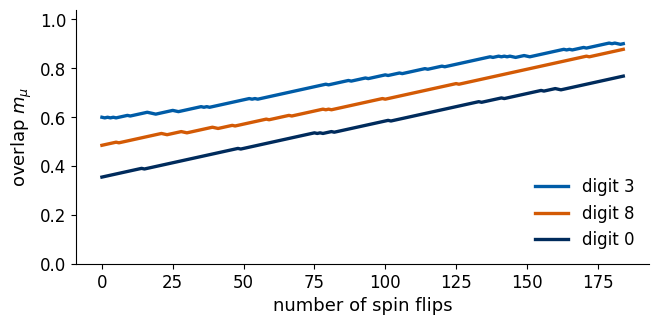

In [29]:
def any_two_outweigh_third(m):
    # the two smallest overlaps together must exceed the largest one, and all must be positive
    ordered = np.sort(m)
    return bool(ordered[0] > 0 and ordered[0] + ordered[1] > ordered[2])

m_start_three = triple @ cue / N_digit                   # equation (7), shape (3,)
m_end_three = triple @ final_three / N_digit
print("overlaps with the digits 3, 8, 0 at the start", m_start_three.round(2).tolist(), " any two outweigh the third:", any_two_outweigh_third(m_start_three))
print("overlaps with the digits 3, 8, 0 at the end  ", m_end_three.round(2).tolist(), " any two outweigh the third:", any_two_outweigh_third(m_end_three))

phi_start = J_three @ cue                                # the fields of the cue, shape (784,)
print("pixels whose field at the start has the majority sign", int(np.sum(np.sign(phi_start) == majority)), "of", N_digit)
print("pixels of the cue that differ from the majority image", int(np.sum(cue != majority)))
print("smallest value of s_i phi_i in the final image", round(float((final_three * (J_three @ final_three)).min()), 3))
print("three-digit overlaps of the final image", m_end_three.round(3).tolist(), "  3/N =", round(3 / N_digit, 4))

path_three_array = np.array(path_three)                  # shape (185, 784)
m_path_three = triple @ path_three_array.T / N_digit     # shape (3, 185)
condition_along_path = [any_two_outweigh_third(m_t) for m_t in m_path_three.T]   # one test per image
# J is symmetric, so entry (t, i) of this product is sum_j s_j J_ji = sum_j J_ij s_j, the field phi_i of image t
fields_along_path = path_three_array @ J_three           # row t holds the fields of image t, shape (185, 784)
majority_field_along_path = np.all(np.sign(fields_along_path) == majority, axis=1)
print("images along the recall that satisfy the condition", sum(condition_along_path), "of", len(path_three))
print("images along the recall whose field has the majority sign at every pixel", int(majority_field_along_path.sum()), "of", len(path_three))
plot_overlap_curves(m_path_three, ["digit 3", "digit 8", "digit 0"], "overload_overlaps")
assert any_two_outweigh_third(m_start_three) and any_two_outweigh_third(m_end_three)
assert np.array_equal(np.sign(phi_start), majority)
assert all(condition_along_path) and majority_field_along_path.all()

The final overlaps $0.90$, $0.88$ and $0.77$ are all positive, and any two of them add up to more than the third. The field of the final image therefore has the majority sign at every pixel, so the majority image is a fixed point, and its smallest value of $s_i\phi_i$ is the margin $0.878+0.768-0.901-3/N=0.741$. The same condition already holds for the cue, whose overlaps are $0.60$, $0.48$ and $0.35$. The printed test shows that the condition holds at all 185 images of the recall and that the field has the majority sign at every pixel of each of them. Each of the 184 pixels at which the cue differs from the majority image is therefore flipped once, which agrees with the 184 flips, and the recall ends there. The cue is closest to the digit 3, but at the 39 outvoted pixels the digits 8 and 0 together carry more weight than the digit 3.

Three patterns are few for 784 spins, and the failure is caused by the similarity of the digits. The next cell repeats the stability test for three random patterns of the same length, drawn from a generator with a fixed seed, with shape `(3, 784)`. Random patterns have small mutual overlaps.

In [30]:
rng_random = np.random.default_rng(78)
random_patterns = rng_random.choice([-1.0, 1.0], size=(3, N_digit))     # shape (3, 784)

Q_random = random_patterns @ random_patterns.T / N_digit
print("largest overlap between two random patterns", round(float(np.abs(Q_random - np.eye(3)).max()), 2))
unstable_counts = [int(np.sum(stability_margin(random_patterns, nu) < -TOL)) for nu in range(3)]
print("pixels against their field in each random pattern", unstable_counts)

largest overlap between two random patterns 0.03
pixels against their field in each random pattern [0, 0, 0]


The random patterns have overlaps of a few hundredths and no unstable pixel. The six portraits, with overlaps of at most $0.3$, were also all stable in Section 6.

## 8. The Mona Lisa, an image never stored

The last test of the core route asks what happens with an image that the network has never seen. We prepare the Mona Lisa in the same way as the portraits, hide its lower half and start the same network of six stored portraits. The outcome depends on the order of the visits. A random generator has an internal state that fixes all numbers it will produce next, and Section 6 saved this state after the six recalls. The next cell restores it, so that this run uses the same visiting order whichever cells were run in between. Its output is the final image `mona_final` of shape `(9216,)`, the overlaps `m_final` of shape `(6,)` with the stored portraits, and the number of pixels of the visible upper half that have changed.

In [31]:
rng_portrait.bit_generator.state = state_after_six       # continue the random sequence after the six recalls
mona_final = relax_portrait(hide_lower_half(mona), xi_portraits, rng_portrait)

m_final = xi_portraits @ mona_final / N_portrait          # equation (7), shape (6,)
m_self = float(mona @ mona_final / N_portrait)
upper = N_portrait // 2                                   # the first half of the vector is the upper half of the image
changed_upper = int(np.sum(mona_final[:upper] != mona[:upper]))

print("overlap of the final image with the true Mona Lisa", round(m_self, 2))
print("pixels of the visible upper half that changed", changed_upper, "of", upper)
for key, value in zip(portrait_keys, m_final):
    print(f"overlap with {key:11s}{value:+.2f}")
assert np.array_equal(mona_final.reshape(n_side, n_side), stored_file["mona_final"])

overlap of the final image with the true Mona Lisa 0.24
pixels of the visible upper half that changed 1210 of 4608
overlap with einstein   -0.25
overlap with ermine     +0.03
overlap with curie      -0.45
overlap with copernicus +0.34
overlap with noether    +0.67
overlap with planck     -0.28


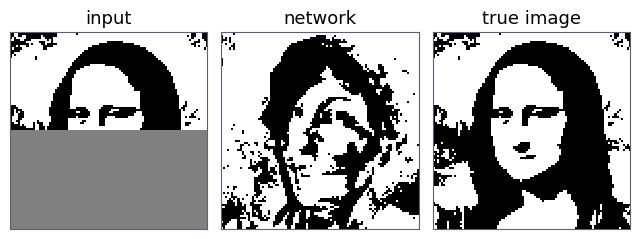

In [32]:
plot_image_row([hide_lower_half(mona), mona_final, mona], ("input", "network", "true image"),
               portrait_shape, "mona_lisa", (8, 3.1))

The output is a stable image, yet it is neither the Mona Lisa nor any stored portrait. Its overlap with the true image is only $0.24$. About a quarter of the visible upper half has changed as well, 1210 of its 4608 pixels, so the network has partly overwritten even what it was shown. The largest overlap, $0.67$, is with the portrait of Noether, and several other portraits contribute with smaller positive or negative overlaps. A negative overlap means that the inverted portrait takes part.

At a fixed point every spin agrees with its field, and the small term $p\,s_i/N$ does not change any sign here, so $s_i=\operatorname{sign}\big(\sum_\mu\xi_i^\mu m_\mu\big)$. The final image is therefore a weighted vote of the six stored portraits, with its own overlaps as the weights. The next cell verifies this. The array `vote` of shape `(9216,)` is the sign of the weighted sum of the portraits, and the cell compares it with the final image and with the closest single portrait.

pixels where the weighted vote differs from the final image 0
pixels where the closest stored portrait differs from it   1501


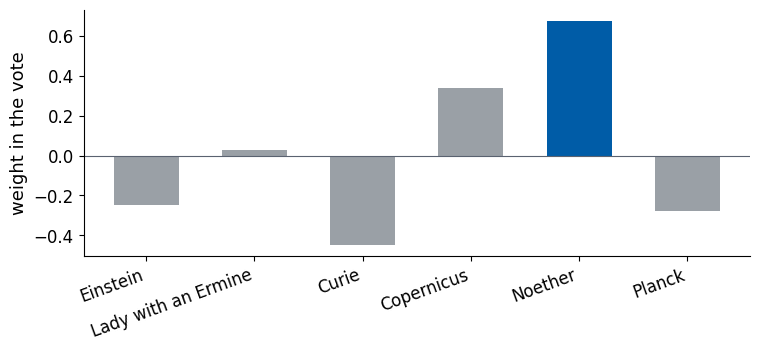

In [33]:
# xi_portraits.T has shape (9216, 6), so this product is sum_mu xi_i^mu m_mu, shape (9216,)
vote = np.sign(xi_portraits.T @ m_final)
assert np.array_equal(vote, mona_final)
assert np.all(mona_final * field_from_overlaps(xi_portraits, mona_final) > 0)     # a fixed point of rule (5)

closest = np.argmax(m_final)
print("pixels where the weighted vote differs from the final image", int(np.sum(vote != mona_final)))
print("pixels where the closest stored portrait differs from it  ", int(np.sum(xi_portraits[closest] != mona_final)))
plot_vote_weights(m_final, labels)

The closest portrait still differs from the final image in 1501 pixels, whereas the weighted vote reproduces every pixel.

### Dependence on the order of the spin updates

The overlaps of the half Mona Lisa at the start are all small, and no stored portrait is clearly ahead, which differs from the six recalls of Section 6. The first flips then influence which combination of portraits grows, so the visiting order can matter. The next cell repeats the recall for 30 different orders, each from its own generator with seed $0,1,\dots,29$. This is a classroom experiment of its own. The lecture quotes a separate run with 40 orders and other seeds, which also ends in two distinct blends, so the counts below need not match the lecture. It keeps a list of the distinct final images, each of shape `(9216,)`, with the number of orders that led to each, and it checks that every final image is a weighted vote of the stored portraits.

In [34]:
m_start_mona = xi_portraits @ hide_lower_half(mona) / N_portrait
print("overlaps of the half Mona Lisa at the start", m_start_mona.round(2).tolist())

outcomes = []                                           # the distinct final images
counts = []                                             # how many orders led to each of them

for seed in range(30):
    final = relax_portrait(hide_lower_half(mona), xi_portraits, np.random.default_rng(seed))
    assert np.array_equal(np.sign(xi_portraits.T @ (xi_portraits @ final / N_portrait)), final)   # weighted vote

    found = False
    for k, outcome in enumerate(outcomes):
        if np.array_equal(outcome, final):
            counts[k] += 1
            found = True
    if not found:
        outcomes.append(final)
        counts.append(1)

print("different final images", len(outcomes))
for outcome, count in sorted(zip(outcomes, counts), key=lambda pair: -pair[1]):
    overlaps = xi_portraits @ outcome / N_portrait
    print(f"{count:2d} of 30 orders   overlap with the Mona Lisa {mona @ outcome / N_portrait:+.2f}   "
          f"changed pixels in the upper half {int(np.sum(outcome[:upper] != mona[:upper]))}")
    print("    overlaps with the portraits", overlaps.round(2).tolist())

most_common = outcomes[int(np.argmax(counts))]
assert sum(counts) == 30 and np.array_equal(most_common, mona_final)

overlaps of the half Mona Lisa at the start [-0.02, 0.01, -0.15, 0.13, 0.21, -0.03]
different final images 2
28 of 30 orders   overlap with the Mona Lisa +0.24   changed pixels in the upper half 1210
    overlaps with the portraits [-0.25, 0.03, -0.45, 0.34, 0.67, -0.28]
 2 of 30 orders   overlap with the Mona Lisa +0.12   changed pixels in the upper half 1602
    overlaps with the portraits [-0.47, -0.07, -0.83, -0.05, 0.29, -0.44]


Of the 30 orders, 28 lead to the image found above, with overlap $0.24$ with the Mona Lisa and $0.67$ with Noether. The other 2 lead to a different image, with overlap $0.12$ with the Mona Lisa, in which the inverted portrait of Curie dominates with overlap $-0.83$ and 1602 pixels of the upper half have changed. The final image therefore depends on the order of the spin updates, and the numbers quoted above describe the most frequent outcome, which is also the outcome of the single run above.

The figure shows the input, the two final images and the true image. Each final image is a weighted vote of the stored portraits, and none of the 30 orders returned the Mona Lisa.

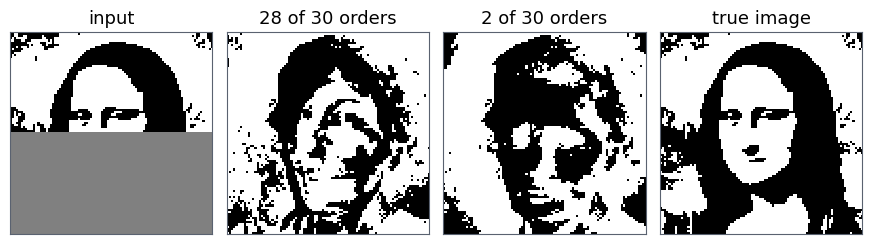

In [35]:
order = np.argsort(counts)[::-1]                        # positions of the outcomes, most frequent first
images = [hide_lower_half(mona)] + [outcomes[k] for k in order] + [mona]
image_titles = ["input"] + [f"{counts[k]} of 30 orders" for k in order] + ["true image"]
plot_image_row(images, image_titles, portrait_shape, "mona_orders", (2.75 * len(images), 3.1))

The core route ends here. Section 9 is work for home, and Exercises 1 to 3 in Section 11 need only the core route. Lab 078 continues with random patterns and measures how many of them the network can hold.

## 9. Exact Boltzmann learning on twelve spins (at home)

The Hebbian rule writes the couplings once and creates false memories such as the mixture state of Section 7. Boltzmann learning [4] improves the couplings by comparing what the network does with what it should do. To follow it without any approximation we use a network so small that all its configurations can be listed.

### Boltzmann distribution

At temperature $T$, with the Boltzmann constant set to one, the network visits a configuration $\mathbf s$ with probability

$$P(\mathbf s)=\frac{e^{-E(\mathbf s)/T}}{Z},\qquad Z=\sum_{\mathbf s}e^{-E(\mathbf s)/T}. \tag{10}$$

The normalising sum $Z$ is called the partition function. Low-energy configurations are the most likely, and raising the temperature spreads the probability over more of them. The four spins of Section 5 show this with their three energy levels. The next cell evaluates equation (10) at two temperatures. The arrays `four_E` and `four_g`, both of shape `(3,)`, hold the three energies and the number of configurations at each energy.

In [36]:
four_E = np.array([-6.0, 0.0, 2.0])                 # the three energies of Section 5
four_g = np.array([2, 8, 6])                        # number of configurations at each energy

for T_four in (2.0, 6.0):
    weights = four_g * np.exp(-four_E / T_four)     # the terms of Z, grouped by energy
    Z = weights.sum()
    print(f"T = {T_four:.0f}   Z = {Z:.2f}   probability of the levels E = -6, 0, 2  ", (weights / Z).round(2).tolist())

T = 2   Z = 50.38   probability of the levels E = -6, 0, 2   [0.8, 0.16, 0.04]
T = 6   Z = 17.74   probability of the levels E = -6, 0, 2   [0.31, 0.45, 0.24]


At $T=2$ most of the probability sits on the two lowest configurations, and at $T=6$ the many higher configurations together carry more of it.

### Learning rule

We want the network to give high probability to a set of $D$ data configurations $\mathbf s^{(d)}$. Because $J$ is symmetric with zero diagonal, the energy (3) equals $E=-\sum_{i\lt j}J_{ij}s_is_j$, a sum in which each pair appears once and the factor $\frac12$ has disappeared. The logarithm of the probability (10) of one configuration is then $\ln P(\mathbf s)=\sum_{i\lt j}J_{ij}s_is_j/T-\ln Z$. Differentiating $\ln Z$ with respect to one coupling brings down $s_i's_j'/T$ inside the sum over configurations $\mathbf s'$,

$$\frac{\partial\ln Z}{\partial J_{ij}}=\frac1Z\sum_{\mathbf s'}\frac{s_i's_j'}{T}\,e^{-E(\mathbf s')/T}=\frac1T\sum_{\mathbf s'}P(\mathbf s')\,s_i's_j',$$

and therefore

$$\frac{\partial\ln P(\mathbf s)}{\partial J_{ij}}=\frac1T\Big(s_is_j-\underbrace{\sum_{\mathbf s'}P(\mathbf s')\,s_i's_j'}_{\langle s_is_j\rangle_{\text{model}}}\Big).$$

We average this over the data, with $\langle s_is_j\rangle_{\text{data}}=\frac1D\sum_{d}s_i^{(d)}s_j^{(d)}$, and take a step uphill. This is gradient ascent on the average log-probability of the data. The factor $1/T$ is absorbed into the learning rate $\eta$, which gives the update

$$\Delta J_{ij}=\eta\big(\langle s_is_j\rangle_{\text{data}}-\langle s_is_j\rangle_{\text{model}}\big). \tag{11}$$

The couplings stop changing when the network reproduces the correlations of the data. The data average is a sum over a few configurations. The model average requires the distribution (10), which we can compute here by listing all configurations.

### Twelve spins with three patterns

We take $N=12$ spins, $p=3$ patterns and $T=1$. The patterns are drawn at random from the generator with seed 1405, and a draw is accepted when two conditions hold. All mutual overlaps must have magnitude at most $1/3$, and each pattern must have an overlap larger than $0.3$ with the majority image, so that the false memory is close to the patterns. Since $E(\mathbf s)=E(-\mathbf s)$, the data consist of the three patterns and their three inverses, $D=6$.

A mixture state of three patterns is the majority vote of the patterns with a chosen sign for each of them,

$$s_i^{\text{mix}}(a,b,c)=\operatorname{sign}\big(a\,\xi_i^1+b\,\xi_i^2+c\,\xi_i^3\big),\qquad a,b,c=\pm1 .$$

The superscripts $1,2,3$ here number the three patterns of this section. The sign variants exist because the inverse of each pattern is also a minimum of the energy, and a vote may include a pattern or its inverse. The three signs give eight combinations, and hence eight mixture states, which form four pairs, since $(-a,-b,-c)$ gives the inverse of the state $(a,b,c)$. The majority image of Section 7 corresponds to $a=b=c=1$, and we follow this state and its inverse in detail.

The next cell performs the selection. Its output is `xi_small` of shape `(3, 12)` and `mix` of shape `(12,)`, the state with $a=b=c=1$.

In [37]:
N_small, p_small, T_model = 12, 3, 1.0
rng_small = np.random.default_rng(1405)

for attempt in range(10000):
    xi_small = rng_small.choice([-1.0, 1.0], size=(p_small, N_small))    # shape (3, 12)
    q_small = xi_small @ xi_small.T / N_small                            # overlaps, shape (3, 3)
    mix = np.sign(xi_small.sum(axis=0))                                  # the majority image, shape (12,)

    largest_mutual_overlap = np.abs(q_small - np.eye(p_small)).max()
    overlaps_with_mix = np.abs(xi_small @ mix) / N_small                 # shape (3,)
    if largest_mutual_overlap <= 1 / 3 + TOL and overlaps_with_mix.min() > 0.3:
        break

print("accepted at attempt", attempt + 1)
print("overlaps between the three patterns")
print(q_small.round(2))
print("overlaps of the mixture with the three patterns", (xi_small @ mix / N_small).round(2).tolist())

accepted at attempt 1
overlaps between the three patterns
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
overlaps of the mixture with the three patterns [0.5, 0.5, 0.5]


The accepted patterns are mutually orthogonal, and the majority image has overlap $0.5$ with each.

The next cell lists all configurations and prepares the two ingredients of the learning rule. The array `S` has shape `(4096, 12)`, with one configuration per row. The data array `data_small` of shape `(6, 12)` holds the patterns and their inverses, and `C_data` of shape `(12, 12)` is the matrix of data correlations $\langle s_is_j\rangle_{\text{data}}$. Learning starts from the Hebbian couplings (2) multiplied by three, `J_hebb` of shape `(12, 12)`, and the following cells show why this factor is used.

In [38]:
# itertools.product lists all 2^12 sequences of twelve values +1 and -1
S = np.array(list(itertools.product([1.0, -1.0], repeat=N_small)))       # shape (4096, 12)

data_small = np.concatenate([xi_small, -xi_small])                       # shape (6, 12)
# data.T @ data has entries sum_d s_i^(d) s_j^(d), and dividing by D gives the average
C_data = data_small.T @ data_small / len(data_small)                     # shape (12, 12)

COUPLING_SCALE = 3.0
J_hebb = COUPLING_SCALE * hebb(xi_small)                                 # three times equation (2)
print("configurations", len(S), "  independent couplings", N_small * (N_small - 1) // 2)

configurations 4096   independent couplings 66


The next cell defines three functions. The function `boltzmann` takes couplings `J` of shape `(12, 12)` and returns the energies `E` and the probabilities `P` of all configurations, each of shape `(4096,)`, from equations (3) and (10). The function `model_correlations` turns `P` into the matrix $\langle s_is_j\rangle_{\text{model}}$ of shape `(12, 12)`. The function `index_of` returns the row of `S` that equals a given configuration.

In [39]:
def boltzmann(J):
    # S @ J has shape (4096, 12). Row r, entry i is sum_j s_j J_ji, which equals the field phi_i of configuration r,
    # equation (4), because J is symmetric.
    fields = S @ J
    # S * fields multiplies entry by entry, and the sum over i gives sum_i s_i phi_i, so this is equation (3)
    E = -0.5 * np.sum(S * fields, axis=1)                                # shape (4096,)

    # subtracting E.min() changes nothing in P, and it keeps the exponentials in a safe numerical range
    weights = np.exp(-(E - E.min()) / T_model)
    return E, weights / weights.sum()                                    # the division by the sum plays the role of Z

def model_correlations(P):
    # P[:, None] has shape (4096, 1), so P[:, None] * S multiplies each row of S by its probability
    return S.T @ (P[:, None] * S)                                        # sum_s P(s) s_i s_j, shape (12, 12)

def index_of(configuration):
    # S == configuration compares every row with it, and np.all(..., axis=1) is True for a row equal in all 12 places
    return int(np.flatnonzero(np.all(S == configuration, axis=1))[0])

pattern_ids = [index_of(x) for x in data_small]                          # rows of the six data configurations
mix_ids = [index_of(mix), index_of(-mix)]                                # the followed mixture state and its inverse

# all eight mixture states, one for each choice of the three signs a, b, c
all_mixture_ids = []
for a, b, c in itertools.product([1, -1], repeat=3):
    state = np.sign(a * xi_small[0] + b * xi_small[1] + c * xi_small[2])
    all_mixture_ids.append(index_of(state))
print("distinct mixture states", len(set(all_mixture_ids)))
assert len(set(all_mixture_ids)) == 8

distinct mixture states 8


The factor three sets the size of the energies relative to the temperature. The next cell compares the Hebbian couplings (2) with the same couplings multiplied by three. It prints the total probability on the six data configurations and the energy of the mixture state above them. With the plain Hebbian couplings the energy differences are comparable with $T=1$ and most of the probability lies elsewhere, whereas at three times the Hebbian scale $T=1$ is a low temperature and the patterns carry most of the probability.

In [40]:
for scale in (1.0, COUPLING_SCALE):
    E, P = boltzmann(scale * hebb(xi_small))
    gap = E[mix_ids].mean() - E[pattern_ids].mean()
    print(f"{scale:.0f} times Hebbian   probability on the patterns {P[pattern_ids].sum():.3f}   mixture energy above the patterns {gap:.2f}")

1 times Hebbian   probability on the patterns 0.063   mixture energy above the patterns 1.50
3 times Hebbian   probability on the patterns 0.834   mixture energy above the patterns 4.50


The function `train_boltzmann` applies equation (11) repeatedly. Its inputs are the starting couplings of shape `(12, 12)`, the learning rate `eta`, the number of updates `steps` and the interval `record_every`. It returns the final couplings and `history`, an array with one row per recorded step and three columns, the step number, the energy of the mixture above the patterns, and the largest correlation mismatch $\max_{ij}|\langle s_is_j\rangle_{\text{data}}-\langle s_is_j\rangle_{\text{model}}|$.

The settings are $N=12$, $p=3$, $T=1$, the pattern selection described above, the starting couplings of three times the Hebbian values, the learning rate $\eta=0.05$ and 6000 updates. The next cell takes a few seconds, because each update sums over all 4096 configurations.

In [41]:
def train_boltzmann(J_start, eta, steps, record_every):
    J = J_start.copy()
    history = []
    for t in range(steps + 1):
        E, P = boltzmann(J)
        difference = C_data - model_correlations(P)              # the bracket in equation (11), shape (12, 12)
        np.fill_diagonal(difference, 0.0)                        # J_ii stays zero

        if t % record_every == 0:                                # % is the remainder of the division
            gap = E[mix_ids].mean() - E[pattern_ids].mean()
            history.append((t, gap, np.abs(difference).max()))

        if t < steps:                                            # step 'steps' is only measured, so there are 'steps' updates
            J += eta * difference                                # equation (11)
    return J, np.array(history)

ETA, STEPS = 0.05, 6000
J_learned, history = train_boltzmann(J_hebb, ETA, STEPS, record_every=60)   # history has shape (101, 3)
print("learning rate", ETA, "  learning steps", STEPS, "  shape of history", history.shape)
print("largest correlation mismatch at the end", round(float(history[-1, 2]), 4))

learning rate 0.05   learning steps 6000   shape of history (101, 3)
largest correlation mismatch at the end 0.0005


### Probabilities and energies after learning

The next cell compares the couplings before and after learning. A false memory can capture a recall as long as it is a valley of the energy, so we also list every local minimum. By equation (6), flipping spin $k$ changes the energy by $2s_k\phi_k$, so a configuration is a local minimum when $s_k\phi_k\ge0$ for all twelve spins. The array `S * (S @ J)` of shape `(4096, 12)` contains all the numbers $s_k\phi_k$. The function `describe` returns a dictionary of the quantities we compare, and the table prints them side by side.

In [42]:
def local_minima(J):
    products = S * (S @ J)                                       # s_k phi_k, shape (4096, 12)
    is_minimum = np.all(products >= -TOL, axis=1)                # True if no single flip lowers the energy
    return set(np.flatnonzero(is_minimum).tolist())              # the rows of S that are local minima

def describe(J):
    E, P = boltzmann(J)
    s_mix = S[mix_ids[0]]
    energy_rises = 2 * s_mix * (s_mix @ J)                       # equation (6) for each of the 12 possible flips
    return {"probability on the stored patterns": P[pattern_ids].sum(),
            "probability outside them": 1 - P[pattern_ids].sum(),
            "probability on the two followed mixture states": P[mix_ids].sum(),
            "probability on all eight mixture states": P[all_mixture_ids].sum(),
            "mean energy of the patterns": E[pattern_ids].mean(),
            "energy of the followed mixture state": E[mix_ids].mean(),
            "mixture energy above the patterns": E[mix_ids].mean() - E[pattern_ids].mean(),
            "smallest energy rise by one flip from the mixture": energy_rises.min()}

before, after_learning = describe(J_hebb), describe(J_learned)
print(f"{'':52s}{'Hebbian':>11s}{'learned':>11s}")
for name in before:
    print(f"{name:52s}{before[name]:11.6f}{after_learning[name]:11.6f}")

minima_before, minima_after = local_minima(J_hebb), local_minima(J_learned)
expected_minima = set(pattern_ids) | set(all_mixture_ids)        # | is the union of two sets
print("local minima, Hebbian and learned couplings", len(minima_before), len(minima_after))
print("they are the six data configurations and the eight mixture states:", minima_before == expected_minima, minima_after == expected_minima)
assert minima_before == expected_minima and minima_after == expected_minima

print("largest correlation mismatch at steps 0, 1020, 3000, 6000:",
      [round(float(history[k, 2]), 4) for k in (0, 17, 50, 100)])

                                                        Hebbian    learned
probability on the stored patterns                     0.834044   0.998433
probability outside them                               0.165956   0.001567
probability on the two followed mixture states         0.003088   0.000019
probability on all eight mixture states                0.012354   0.000077
mean energy of the patterns                          -13.500000 -27.102391
energy of the followed mixture state                  -9.000000 -17.346687
mixture energy above the patterns                      4.500000   9.755704
smallest energy rise by one flip from the mixture      1.500000   2.530328
local minima, Hebbian and learned couplings 14 14
they are the six data configurations and the eight mixture states: True True
largest correlation mismatch at steps 0, 1020, 3000, 6000: [0.0573, 0.0027, 0.001, 0.0005]


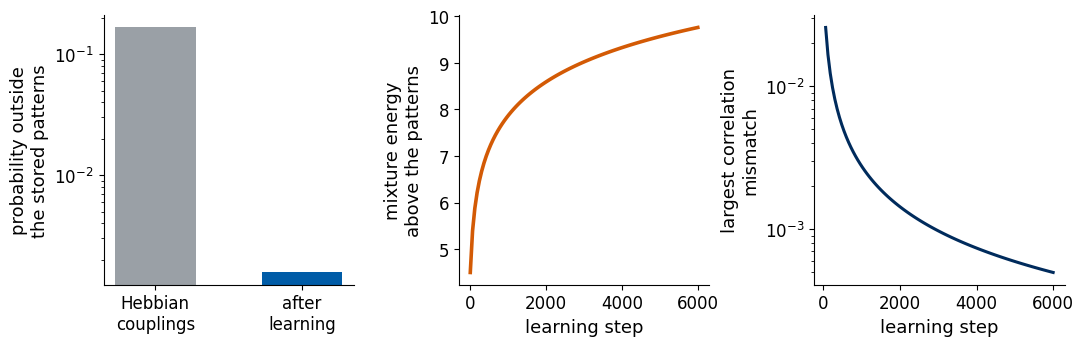

In [43]:
plot_boltzmann(before["probability outside them"], after_learning["probability outside them"], history)

Learning concentrates the probability on the stored patterns, and the probability outside them drops from $0.17$ to $0.0016$, as the left panel shows on a logarithmic axis. The followed mixture state moves up relative to the patterns, since its energy above them grows from $4.50$ to $9.76$ in the middle panel. Both energies fall in absolute terms, the patterns faster than the mixture, so this rise is a statement about the gap.

The right panel shows the largest correlation mismatch, which falls steadily and reaches $0.0005$ after 6000 updates with $\eta=0.05$. At late times it shrinks roughly in inverse proportion to the number of updates, as the printed values show. The learning rate matters here, and Exercise 4 shows what a larger value does.

The followed mixture state remains a local minimum, and the smallest energy rise caused by one flip even grows, from $1.50$ to $2.53$. All 14 local minima of the Hebbian network, the six data configurations and the eight mixture states defined above, are still present after learning. A recall by rule (5) that reaches a mixture state therefore still stays there, while sampling at temperature $T=1$ visits the two followed mixture states with a probability of only about $2\times10^{-5}$. Equation (11) returns in Lab 079, where hidden units are added and the model average is estimated by sampling.

## 10. Summary

An image becomes a pattern of spins $\pm1$, and the Hebbian rule stores patterns by adding their outer products into the couplings. The couplings define an energy, and aligning one spin at a time with its local field lowers this energy at every flip until the network stops in a local minimum. Two separate questions decide the outcome of a recall. A pattern is stable when its own vote outweighs the votes of the other patterns at every pixel, and a stable pattern is reached when the cue favours it through the overlaps. In this way a damaged digit was repaired, and six portraits came back from their upper halves with no wrong pixel. A third, similar digit made all three digits unstable, and the network ended at their majority image, because the overlaps of the cue and of the final image let any two digits outvote the third. The Mona Lisa, which was never stored, ended as a weighted vote of the six portraits, and the vote that resulted depended on the order of the spin updates. In the small network of Section 9, Boltzmann learning with $\eta=0.05$ matched the correlations of the data, raised the false memories relative to the patterns and made them improbable, while they stayed local minima.

The next cell prints the run time of the notebook up to this point. The exercises below are not included in it.

In [44]:
print(f"run time of the whole notebook {time.time() - START:.1f} s")
print("figures written to", FIG)

run time of the whole notebook 24.0 s
figures written to figures_lab078a


## 11. Exercises

Each exercise has a hint and a code cell. Write your computation in that cell, replace `None` by your result, and run it. The check function compares your result with a reference computed with the same settings, and it prints a hint when something differs. Exercises 1 to 3 need only the core route, and Exercise 4 needs Section 9. The next cell contains the check functions and is collapsed, because reading it would reveal the answers.

In [45]:
def check_exercise_1(to_eight):
    fractions, seeds = (0.30, 0.40, 0.45, 0.48), range(40)
    if to_eight is None:
        print("Exercise 1, no answer yet. Expected form {0.30: count, 0.40: count, 0.45: count, 0.48: count}.")
        return
    reference, larger_wins = {}, 0
    for fraction in fractions:
        reference[fraction] = 0
        for seed in seeds:
            rng = np.random.default_rng(seed)
            damaged_cue, _ = damage(three, fraction, rng)
            final, _ = relax(J_two, damaged_cue, rng)
            ends_at_eight = np.array_equal(final, eight)
            reference[fraction] += int(ends_at_eight)
            larger_wins += int(ends_at_eight == (eight @ damaged_cue > three @ damaged_cue))
    if {f: to_eight.get(f) for f in fractions} == reference:
        print("Exercise 1 is correct. Runs ending at the digit 8 out of 40:", reference)
        print(f"The digit with the larger initial overlap was reached in {larger_wins} of {40 * len(fractions)} runs.")
    else:
        print("Exercise 1 differs from the reference. Use one generator per run, default_rng(seed), first for damage")
        print("and then for relax, and remember that relax returns the pair (final, path).")

def check_exercise_2(n_unstable, n_outvoted, n_shared):
    if n_unstable is None or n_outvoted is None or n_shared is None:
        print("Exercise 2, no answer yet.")
        return
    one = xi_digits[1]
    digits_new = np.array([three, eight, one])
    unstable = stability_margin(digits_new, 0) < -TOL
    outvoted = (eight != three) & (one != three)
    outvoted_zero = (eight != three) & (zero != three)
    correct = (int(unstable.sum()), int(outvoted.sum()), int(np.sum(outvoted & outvoted_zero)))
    if (n_unstable, n_outvoted, n_shared) == correct:
        print("Exercise 2 is correct:", correct)
        print("Both digit sets give 39 outvoted pixels, yet only part of these pixels coincide, so the equal counts are a coincidence of these digit images.")
    else:
        print("Exercise 2 differs from the reference. Build the masks with != and combine them with &.")

def check_exercise_3(wrong_counts):
    if wrong_counts is None:
        print("Exercise 3, no answer yet. Expected an array of shape (3, 7).")
        return
    seven = np.vstack([xi_portraits, mona])
    reference = []
    for seed in range(3):
        rng = np.random.default_rng(seed)
        reference.append([int(np.sum(relax_portrait(hide_lower_half(x), seven, rng) != x)) for x in seven])
    reference = np.array(reference)
    if np.array_equal(np.asarray(wrong_counts), reference):
        print("Exercise 3 is correct. Portraits with wrong pixels in every order:",
              [(["Einstein", "Ermine", "Curie", "Copernicus", "Noether", "Planck", "Mona Lisa"])[j] for j in np.flatnonzero((reference > 0).all(axis=0))])
    else:
        print("Exercise 3 differs from the reference. Use one generator default_rng(seed) for all seven recalls of one order.")

def check_exercise_4(median_large, median_small):
    if median_large is None or median_small is None:
        print("Exercise 4, no answer yet.")
        return
    results = []
    for eta in (0.15, 0.05):
        _, recorded = train_boltzmann(J_hebb, eta, 2000, record_every=1)
        results.append(float(np.median(recorded[-200:, 2])))
    if abs(median_large - results[0]) < 0.02 and abs(median_small - results[1]) < 0.001:
        print(f"Exercise 4 is correct. Median mismatch of the last 200 steps, eta = 0.15 {results[0]:.3f}, eta = 0.05 {results[1]:.4f}.")
    else:
        print("Exercise 4 differs from the reference. Call train_boltzmann(J_hebb, eta, 2000, record_every=1) and use history[-200:, 2].")

### Exercise 1. Damage

Damage the digit 3 by the fractions 0.30, 0.40, 0.45 and 0.48, and let the network that stores the digits 3 and 8 relax. One random seed can mislead here, because near the highest fractions the outcome changes from one damaged image to another. Use the 40 seeds $0,\dots,39$ for every fraction, and count how many runs end at the digit 8. Then explain the trend with the overlaps (7) of the cue.

The hint for one run is `rng = np.random.default_rng(seed)`, followed by `cue_new, _ = damage(three, fraction, rng)` and `final, _ = relax(J_two, cue_new, rng)`. The function `relax` returns a pair, and the underscore discards the part we do not need. Use `np.array_equal(final, eight)` to test the end point. For the explanation, compare `three @ cue_new` with `eight @ cue_new` in each run.

In [46]:
# Write your computation here. The result is a dictionary with the four fractions as keys and the counts as values.
to_eight = None

check_exercise_1(to_eight)

Exercise 1, no answer yet. Expected form {0.30: count, 0.40: count, 0.45: count, 0.48: count}.


### Exercise 2. Another third digit

Replace the digit 0 of Section 7 by the digit 1, `xi_digits[1]`, and store the digits 3, 8 and 1. Equation (9) gives the sign of $\xi_i^{(3)}\phi_i$ at a pixel where both other digits differ from the digit 3. The number of unstable pixels then follows from counting these pixels, so a count of the outvoted pixels should agree with the run. Compute `n_unstable`, the number of pixels with a negative margin, using `stability_margin`, and `n_outvoted`, the number of pixels where both the 8 and the 1 differ from the 3. Compute also `n_shared`, the number of those outvoted pixels that are outvoted in the case of the digit 0 as well.

The hint is that `(eight != three) & (xi_digits[1] != three)` is the mask of the outvoted pixels, and `mask.sum()` counts them. Convert each count to a Python integer with `int(...)`.

In [47]:
n_unstable = None
n_outvoted = None
n_shared = None

check_exercise_2(n_unstable, n_outvoted, n_shared)

Exercise 2, no answer yet.


### Exercise 3. A seventh portrait

Add the Mona Lisa to the stored patterns with `seven = np.vstack([xi_portraits, mona])`, which has shape `(7, 9216)`. For the three seeds 0, 1 and 2, create one generator `rng = np.random.default_rng(seed)`, recall all seven images from their upper halves in the order of the rows of `seven` with `relax_portrait(hide_lower_half(x), seven, rng)`, and count the wrong pixels of each. Collect the counts in an array `wrong_counts` of shape `(3, 7)`, with one row per seed.

Check also whether each of the seven patterns is still stable by computing `stability_margin(seven, nu).min()`, and evaluate the margin at the start as in Section 6. The hint is that stability and recall are separate questions, as in Section 5, so a portrait can be stable and still be missed from its half cue. A negative start margin only removes the guarantee that the correct portrait wins everywhere from the start, so it does not by itself decide the outcome.

In [48]:
wrong_counts = None

check_exercise_3(wrong_counts)

Exercise 3, no answer yet. Expected an array of shape (3, 7).


### Exercise 4. Learning rate (needs Section 9)

Train the twelve-spin network for 2000 updates with `train_boltzmann(J_hebb, eta, 2000, record_every=1)`, once with $\eta=0.15$ and once with $\eta=0.05$, and compute for each the median of the correlation mismatch over the last 200 steps, `np.median(history_eta[-200:, 2])`. Plot the mismatch of the last 50 steps for both values of $\eta$ and describe the difference. The hint is that a good learning curve is one whose mismatch settles, so a single value at the last step can be misleading when the curve oscillates.

In [49]:
median_large = None      # the median for eta = 0.15
median_small = None      # the median for eta = 0.05

check_exercise_4(median_large, median_small)

Exercise 4, no answer yet.


## References

[1] J. J. Hopfield, Neural networks and physical systems with emergent collective computational abilities, Proc. Natl. Acad. Sci. USA **79**, 2554 (1982), doi:[10.1073/pnas.](https://doi.org/10.1073/pnas.).

[2] Y. LeCun, L. Bottou, Y. Bengio and P. Haffner, Gradient-based learning applied to document recognition, Proc. IEEE **86**, 2278 (1998), doi:[10.1109/5.726791](https://doi.org/10.1109/5.726791).

[3] D. O. Hebb, The Organization of Behavior (Wiley, New York, 1949), reissued by Psychology Press (2005), doi:[10.4324/9781410612403](https://doi.org/10.4324/9781410612403).

[4] D. H. Ackley, G. E. Hinton and T. J. Sejnowski, A learning algorithm for Boltzmann machines, Cogn. Sci. **9**, 147 (1985), doi:[10.1207/s15516709cog0901_7](https://doi.org/10.1207/s15516709cog0901_7).

## Image sources

All images are in the public domain and were obtained from Wikimedia Commons.

| Image | Author | Date | Source |
|---|---|---|---|
| Albert Einstein | Ferdinand Schmutzer | 1921 | [Einstein1921 by F Schmutzer 4.jpg](https://commons.wikimedia.org/wiki/File:Einstein1921_by_F_Schmutzer_4.jpg) |
| Lady with an Ermine | Leonardo da Vinci | about 1490 | [Lady with an Ermine, Google Art Project](https://commons.wikimedia.org/wiki/File:Lady_with_an_Ermine_-_Leonardo_da_Vinci_-_Google_Art_Project.jpg) |
| Marie Curie | Henri Manuel | about 1920 | [Marie Curie c. 1920s.jpg](https://commons.wikimedia.org/wiki/File:Marie_Curie_c._1920s.jpg) |
| Nicolaus Copernicus | unknown author | about 1580 | [Nikolaus Kopernikus.jpg](https://commons.wikimedia.org/wiki/File:Nikolaus_Kopernikus.jpg) |
| Emmy Noether | unknown author | before 1910 | [Noether.jpg](https://commons.wikimedia.org/wiki/File:Noether.jpg) |
| Max Planck | unknown author, credited to Transocean Berlin | about 1930 | [Max Planck (1858-1947).jpg](https://commons.wikimedia.org/wiki/File:Max_Planck_(1858-1947).jpg) |
| Mona Lisa | Leonardo da Vinci | between 1503 and 1506 | [Mona Lisa, C2RMF retouched](https://commons.wikimedia.org/wiki/File:Mona_Lisa,_by_Leonardo_da_Vinci,_from_C2RMF_retouched.jpg) |